# Primordial Black Holes in Dark Dimensions 




In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import FixedLocator, FuncFormatter, LogLocator, NullFormatter, AutoMinorLocator
from matplotlib.patches import Ellipse, Circle
from scipy.special import gamma, log_ndtr
from scipy.interpolate import PchipInterpolator
from scipy.stats import chi2
from IPython.display import display

OUT = Path('DD_Review_All_Figures')
DATA = OUT / 'data'
OUT.mkdir(exist_ok=True, parents=True)
DATA.mkdir(exist_ok=True, parents=True)

C = dict(dark='#24364F', navy='#1D4179', blue='#1479C8', purple='#8051C9',
         teal='#078E8E', green='#238C5A', orange='#E18225', rose='#CA4B89',
         red='#D64A5C', gray='#6E7B8C')
PASTEL = dict(rose='#F9D6E1', red='#F8D9DD', green='#DFF4E5',
              teal='#D7F4EF', blue='#D9E9FC', orange='#FFE1C2', purple='#E7DEFC')

mpl.rcParams.update({
    'font.family': 'DejaVu Sans',
    'mathtext.fontset': 'dejavusans',
    'mathtext.default': 'bf',
    'figure.dpi': 105,
    'savefig.dpi': 220,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 2.1,
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
})

# ---------- Physical constants and benchmark ----------
MPL = 2.435e18            # reduced 4D Planck mass [GeV]
G_TO_GEV = 5.609588603e23 # 1 gram in GeV (c=1)
GEV_INV_M = 1.973269804e-16
YEAR_S = 365.25*24*3600
AGE_YR = 13.8e9
R_M = 1.0e-6              # geometric torus radius [m]
R_GEV = R_M / GEV_INV_M   # radius [GeV^-1]
L_GEV = 2*np.pi*R_GEV     # torus circumference [GeV^-1]
GAMMA_COLLAPSE = .2
A_PR = .022
WIDTH = .72

# ---------- Robust mathematical tick formatting ----------
def bold_power10(value, pos):
    if value <= 0 or not np.isfinite(value):
        return ''
    n = int(np.rint(np.log10(value)))
    if not np.isclose(np.log10(value), n, atol=1e-8):
        return ''
    return rf'$\mathbf{{10}}^{{\mathbf{{{n}}}}}$'

def style(ax, logx=False, logy=False, label=22, ticks=18, xexp=None, yexp=None):
    if logx:
        ax.set_xscale('log')
        ax.xaxis.set_major_locator(FixedLocator(10.**np.array(xexp,dtype=float)) if xexp is not None
                                   else LogLocator(base=10,numticks=7))
        ax.xaxis.set_major_formatter(FuncFormatter(bold_power10))
        ax.xaxis.set_minor_locator(LogLocator(base=10,subs=(2,5),numticks=80))
        ax.xaxis.set_minor_formatter(NullFormatter())
    else:
        ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    if logy:
        ax.set_yscale('log')
        ax.yaxis.set_major_locator(FixedLocator(10.**np.array(yexp,dtype=float)) if yexp is not None
                                   else LogLocator(base=10,numticks=7))
        ax.yaxis.set_major_formatter(FuncFormatter(bold_power10))
        ax.yaxis.set_minor_locator(LogLocator(base=10,subs=(2,5),numticks=80))
        ax.yaxis.set_minor_formatter(NullFormatter())
    else:
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(which='major',direction='in',top=True,right=True,
                   width=2.4,length=10,labelsize=ticks,pad=8)
    ax.tick_params(which='minor',direction='in',top=True,right=True,
                   width=1.5,length=5.5)
    for t in ax.get_xticklabels()+ax.get_yticklabels():
        t.set_weight('bold')
        t.set_fontsize(ticks)
    for spine in ax.spines.values(): spine.set_linewidth(2.1)
    ax.grid(which='major',ls='--',lw=.8,alpha=.19)
    ax.set_axisbelow(True)
    ax.xaxis.label.set_fontsize(label)
    ax.yaxis.label.set_fontsize(label)
    ax.xaxis.label.set_weight('bold')
    ax.yaxis.label.set_weight('bold')
    ax.set_facecolor('#FCFDFF')

def box(ax, text, x, y, color='blue', fs=14, fc='white', ha='left'):
    col=C.get(color,color)
    return ax.text(x,y,text,transform=ax.transAxes,ha=ha,va='center',
                   fontsize=fs,fontweight='bold',color=col,zorder=20,
                   bbox=dict(boxstyle='round,pad=.32',fc=fc,ec=col,lw=1.5,alpha=.97))

def legend(ax,loc='best',fs=15,ncol=1,**kwargs):
    lg=ax.legend(loc=loc,fontsize=fs,ncol=ncol,frameon=True,fancybox=True,
                 framealpha=.97,facecolor='white',edgecolor=C['gray'],
                 labelspacing=.45,borderpad=.57,**kwargs)
    if lg:
        lg.get_frame().set_linewidth(1.5)
        for t in lg.get_texts(): t.set_weight('bold')
    return lg

def save_show(fig,name,dpi=220):
    fig.savefig(OUT/(name+'.pdf'),bbox_inches='tight',facecolor='white')
    fig.savefig(OUT/(name+'.png'),dpi=dpi,bbox_inches='tight',facecolor='white')
    display(fig)
    plt.close(fig)
    print('Saved:', name+'.pdf / .png')

# ---------- Higher-dimensional horizon/entropy/temperature ----------
def sphere_area(D):
    return 2*np.pi**((D-1)/2)/gamma((D-1)/2)

def MD_dim(D):
    n=D-4
    return (MPL**2 / L_GEV**n)**(1/(n+2)) if D>4 else MPL

def r_h(mass_g,D):
    M=np.asarray(mass_g,dtype=float)*G_TO_GEV
    return (2*M/((D-2)*sphere_area(D)*MD_dim(D)**(D-2)))**(1/(D-3))

def S_bh(mass_g,D):
    return 2*np.pi*sphere_area(D)*(MD_dim(D)*r_h(mass_g,D))**(D-2)

def T_h(mass_g,D):
    return (D-3)/(4*np.pi*r_h(mass_g,D))

def cross_mass_g(D):
    return ((D-2)*sphere_area(D)*MD_dim(D)**(D-2)*R_GEV**(D-3)/2)/G_TO_GEV

# ---------- Lifetime prescriptions from the research notebook ----------
def log_tau0_years(mg,D):
    z=np.log10(np.asarray(mg,dtype=float))
    if D==5:
        return np.log10(2.78e-15)+2*z+3*np.log10(1e10/MD_dim(5))
    if D==6:
        return np.log10(13.7e9)+(5/3)*(z-8)+(8/3)*np.log10(1e4/MD_dim(6))
    raise ValueError('D must be 5 or 6')

def log_tau_years(mg,D,p):
    B=(D-1)/(D-3)
    E=(D-1+p*(D-2))/(D-3)
    return log_tau0_years(mg,D)+p*np.log10(S_bh(mg,D))+np.log10(B/E)

# ---------- Radiation-era (4D) benchmark mass-frequency mapping ----------
def peak_k(mg):
    return 7e13*np.sqrt(1e18/np.asarray(mg,dtype=float))

def peak_f(mg):
    return .11*np.sqrt(1e18/np.asarray(mg,dtype=float))

def Hformation_ev(mg):
    return 1e9*(4*np.pi*GAMMA_COLLAPSE*MPL**2/(np.asarray(mg)*G_TO_GEV))

mKK_ev = 1e9/R_GEV
mkk_invL_ev = 1e9/L_GEV
Mcrit_phys_g = 1e9*(4*np.pi*GAMMA_COLLAPSE*MPL**2)/(mKK_ev*G_TO_GEV)
Mcrit_invL_g = 1e9*(4*np.pi*GAMMA_COLLAPSE*MPL**2)/(mkk_invL_ev*G_TO_GEV)
print(f'5D: M5={MD_dim(5):.4e} GeV; 6D: M6={MD_dim(6):.4e} GeV')
print(f'KK gap = {mKK_ev:.4f} eV; 1/L alternative = {mkk_invL_ev:.4f} eV')
print(f'Formation proxy Mcrit(1/R)={Mcrit_phys_g:.4e} g; (1/L)={Mcrit_invL_g:.4e} g')

5D: M5=5.7104e+08 GeV; 6D: M6=8.7449e+03 GeV
KK gap = 0.1973 eV; 1/L alternative = 0.0314 eV
Formation proxy Mcrit(1/R)=1.3462e+23 g; (1/L)=8.4586e+23 g


## Draft Figure 1 — PBH lifetimes, GW frequencies, and the formation threshold


The reduced fundamental scale and KK gap use

$$
\overline M_{\rm Pl}^{\,2}=(2\pi R)^n M_{4+n}^{n+2},\qquad
m_{\rm KK}^{(1)}=\frac{1}{R},\qquad L=2\pi R.
$$

The illustrative lifetime is built from

$$
\log_{10}\tau_{D,p}=\log_{10}\tau_{D,0}
+p\log_{10}S_D+\log_{10}\left[\frac{B_D}{E_{D,p}}\right],
\quad B_D=\frac{D-1}{D-3},\quad E_{D,p}=\frac{D-1+p(D-2)}{D-3}.
$$

The benchmark four-dimensional radiation-era mapping is

$$
H_f\simeq\frac{4\pi\gamma\overline M_{\rm Pl}^{\,2}}{M_{\rm PBH}},\qquad
f_*\simeq0.11\,\mathrm{Hz}\left(\frac{M_{\rm PBH}}{10^{18}\,\mathrm g}\right)^{-1/2},\quad\gamma=0.2.
$$

The lifetime band is **not** an observationally allowed dark-matter region; detector bands are **not** sensitivity bounds. The Region I/II division is the formation *background* proxy $H_f=1/R$, not a calculation of massive tensor excitation.

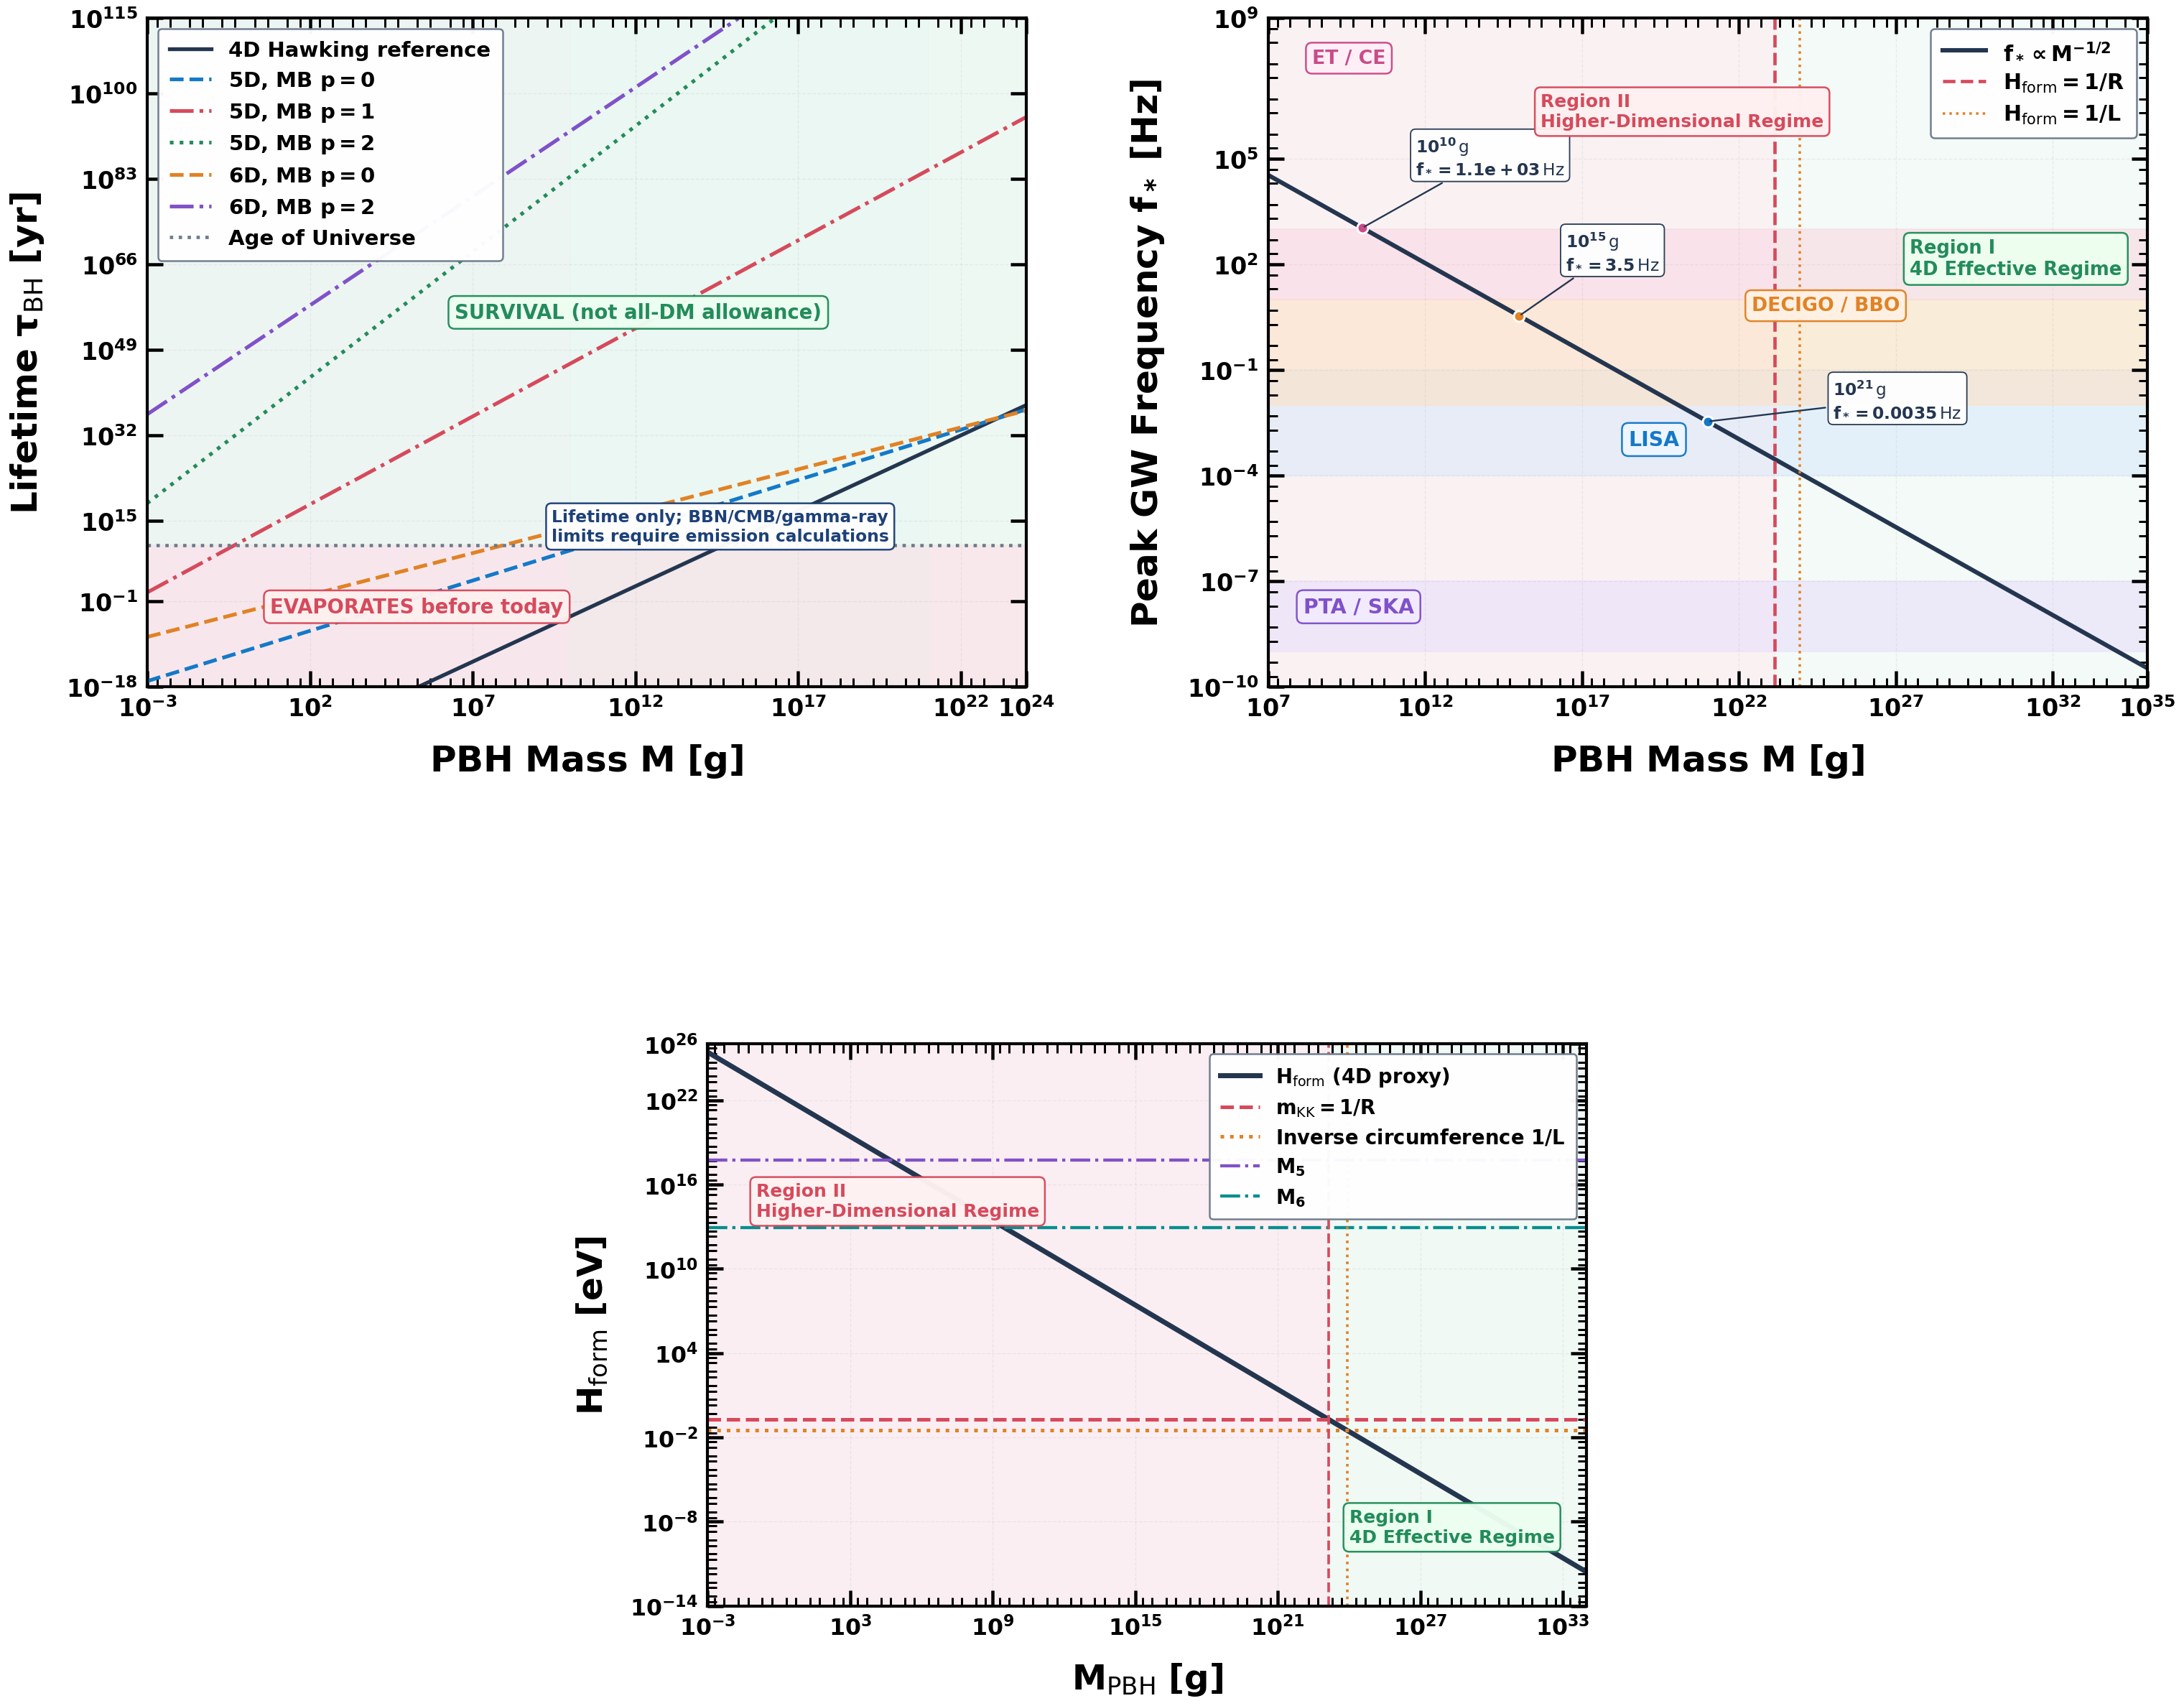

Saved: Fig1_Overview_Three_Panels.pdf / .png
Figure 1 generated successfully.
Region I : 4D Effective Regime
Region II: Higher-Dimensional Regime


In [16]:

# ==============================================================
# FIGURE 1: PBH LIFETIMES, GW FREQUENCIES AND KK SCALES
#
# TOP LEFT:
# 4D, 5D AND 6D PBH LIFETIMES WITH MEMORY BURDEN
#
# TOP RIGHT:
# PBH MASS VERSUS CHARACTERISTIC GW FREQUENCY
#
# BOTTOM CENTER:
# FORMATION HUBBLE SCALE AND KK THRESHOLDS
#
# REGION I  : 4D EFFECTIVE REGIME
# REGION II : HIGHER-DIMENSIONAL REGIME
#
# LARGE BOLD LABELS, TICKS, LEGENDS AND ANNOTATIONS
# ==============================================================

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------------------
# FIGURE LAYOUT
# --------------------------------------------------------------
fig = plt.figure(figsize=(25.5, 20.7))

gs = fig.add_gridspec(
    2, 4,
    left=0.075,
    right=0.985,
    bottom=0.075,
    top=0.965,
    wspace=0.76,
    hspace=0.58,
    height_ratios=[1.0, 0.84]
)

ax = fig.add_subplot(gs[0, 0:2])
ay = fig.add_subplot(gs[0, 2:4])
az = fig.add_subplot(gs[1, 1:3])

# ==============================================================
# TOP LEFT: ORIGINAL PBH LIFETIME FIGURE
# ==============================================================

mass = np.geomspace(1e-3, 1e24, 810)

Y_LO = 1e-18
Y_HI = 1e115

# --------------------------------------------------------------
# SURVIVAL AND EVAPORATION REGIONS
# --------------------------------------------------------------
ax.axhspan(
    Y_LO, AGE_YR,
    color=PASTEL['red'],
    alpha=0.56,
    zorder=0
)

ax.axhspan(
    AGE_YR, Y_HI,
    color=PASTEL['green'],
    alpha=0.45,
    zorder=0
)

ax.axvspan(
    1e10, 1e21,
    color=PASTEL['teal'],
    alpha=0.16,
    zorder=0
)

ax.axvspan(
    1e-3, 1e10,
    color=PASTEL['purple'],
    alpha=0.08,
    zorder=0
)

# --------------------------------------------------------------
# STANDARD 4D HAWKING REFERENCE
# --------------------------------------------------------------
t4 = AGE_YR * (mass / 5e14)**3

ax.plot(
    mass,
    t4,
    color=C['dark'],
    lw=3.2,
    ls='-',
    label='4D Hawking reference'
)

# --------------------------------------------------------------
# 5D AND 6D MEMORY-BURDEN LIFETIMES
# --------------------------------------------------------------
for D, p, col, ls in [
    (5, 0, C['blue'], '--'),
    (5, 1, C['red'], '-.'),
    (5, 2, C['green'], ':'),
    (6, 0, C['orange'], '--'),
    (6, 2, C['purple'], '-.')
]:

    lt = log_tau_years(mass, D, p)

    vals = np.power(
        10.0,
        np.clip(lt, -18, 115)
    )

    vals[(lt > 115) | (lt < -18)] = np.nan

    ax.plot(
        mass,
        vals,
        lw=3.1,
        color=col,
        ls=ls,
        label=fr'{D}D, MB $p={p}$'
    )

# --------------------------------------------------------------
# AGE OF UNIVERSE
# --------------------------------------------------------------
ax.axhline(
    AGE_YR,
    color=C['gray'],
    lw=2.8,
    ls=':',
    label='Age of Universe'
)

ax.set_xlim(1e-3, 1e24)
ax.set_ylim(Y_LO, Y_HI)

ax.set_xlabel(
    r'$\mathbf{PBH\ Mass}\ \mathbf{M}\ [\mathbf{g}]$',
    labelpad=17
)

ax.set_ylabel(
    r'$\mathbf{Lifetime}\ \tau_{\rm BH}\ [\mathbf{yr}]$',
    labelpad=17
)

style(
    ax, True, True,
    label=30,
    ticks=20,
    xexp=[-3, 2, 7, 12, 17, 22, 24],
    yexp=[-18, -1, 15, 32, 49, 66, 83, 100, 115]
)

legend(
    ax,
    'upper left',
    fs=17.5
)

# --------------------------------------------------------------
# ORIGINAL LIFETIME ANNOTATIONS
# --------------------------------------------------------------
box(
    ax,
    'SURVIVAL (not all-DM allowance)',
    .35, .56,
    'green', 16.5,
    fc='#EDFFF1'
)

box(
    ax,
    'EVAPORATES before today',
    .14, .12,
    'red', 16.5,
    fc='#FFF0F0'
)

box(
    ax,
    'Lifetime only; BBN/CMB/gamma-ray\n'
    'limits require emission calculations',
    .46, .24,
    'navy', 14,
    fc='white'
)

# ==============================================================
# TOP RIGHT: PBH MASS AND GW FREQUENCY
# ==============================================================

M_GRID = np.geomspace(1e7, 1e35, 840)

F_GRID = peak_f(M_GRID)

# --------------------------------------------------------------
# REGION I AND REGION II BACKGROUNDS
# --------------------------------------------------------------
ay.axvspan(
    1e7, Mcrit_phys_g,
    color=PASTEL['red'],
    alpha=0.33,
    zorder=0
)

ay.axvspan(
    Mcrit_phys_g, 1e35,
    color=PASTEL['green'],
    alpha=0.28,
    zorder=0
)

# --------------------------------------------------------------
# DETECTOR FREQUENCY BANDS
# --------------------------------------------------------------
for f1, f2, col in [
    (1e-9, 1e-7, PASTEL['purple']),
    (1e-4, 1e-1, PASTEL['blue']),
    (1e-2, 10, PASTEL['orange']),
    (10, 1e3, PASTEL['rose'])
]:

    ay.axhspan(
        f1, f2,
        color=col,
        alpha=0.55,
        zorder=0
    )

# --------------------------------------------------------------
# GW MASS-FREQUENCY RELATION
# --------------------------------------------------------------
ay.plot(
    M_GRID,
    F_GRID,
    color=C['dark'],
    lw=3.65,
    label=r'$f_*\propto M^{-1/2}$'
)

# --------------------------------------------------------------
# KK TRANSITION THRESHOLDS
# --------------------------------------------------------------
ay.axvline(
    Mcrit_phys_g,
    color=C['red'],
    lw=2.8,
    ls='--',
    label=r'$H_{\rm form}=1/R$'
)

ay.axvline(
    Mcrit_invL_g,
    color=C['orange'],
    lw=2.1,
    ls=':',
    label=r'$H_{\rm form}=1/L$'
)

# --------------------------------------------------------------
# PBH BENCHMARK POINTS
# --------------------------------------------------------------
for m0, col in [
    (1e10, C['rose']),
    (1e15, C['orange']),
    (1e21, C['blue'])
]:

    ay.plot(
        [m0],
        [peak_f(m0)],
        marker='o',
        markersize=9,
        mec='white',
        mew=1.8,
        color=col,
        zorder=13
    )

ay.set_xlim(1e7, 1e35)
ay.set_ylim(1e-10, 1e9)

ay.set_xlabel(
    r'$\mathbf{PBH\ Mass}\ \mathbf{M}\ [\mathbf{g}]$',
    labelpad=17
)

ay.set_ylabel(
    r'$\mathbf{Peak\ GW\ Frequency}\ f_*\ [\mathbf{Hz}]$',
    labelpad=17
)

style(
    ay, True, True,
    label=30,
    ticks=20,
    xexp=[7, 12, 17, 22, 27, 32, 35],
    yexp=[-10, -7, -4, -1, 2, 5, 9]
)

legend(
    ay,
    'upper right',
    fs=18
)

# --------------------------------------------------------------
# UPDATED SCIENTIFIC REGION NAMES
# --------------------------------------------------------------

# REGION II
box(
    ay,
    'Region II\nHigher-Dimensional Regime',
    .31, .86,
    'red', 15,
    fc='#FFF0F0'
)

# REGION I
box(
    ay,
    'Region I\n4D Effective Regime',
    .73, .64,
    'green', 15.5,
    fc='#EDFFF0'
)

# --------------------------------------------------------------
# DETECTOR LABELS
# --------------------------------------------------------------
box(
    ay,
    'PTA / SKA',
    .04, .12,
    'purple', 17,
    fc='#F3EBFF'
)

box(
    ay,
    'LISA',
    .41, .37,
    'blue', 17,
    fc='#EFF6FF'
)

box(
    ay,
    'DECIGO / BBO',
    .55, .57,
    'orange', 16,
    fc='#FFF1E4'
)

box(
    ay,
    'ET / CE',
    .05, .94,
    'rose', 16,
    fc='#FFEFF7'
)

# --------------------------------------------------------------
# ORIGINAL BENCHMARK ANNOTATIONS
# --------------------------------------------------------------
for m0, offset in [
    (1e10, (5e11, 4e4)),
    (1e15, (3e16, 8e1)),
    (1e21, (1e25, 5e-3))
]:

    f0 = peak_f(m0)

    benchmark_text = (
        fr'$10^{{{int(np.log10(m0))}}}\,\mathrm{{g}}$'
        + '\n'
        + fr'$f_*={f0:.2g}\,\mathrm{{Hz}}$'
    )

    ay.annotate(
        benchmark_text,
        xy=(m0, f0),
        xytext=offset,
        textcoords='data',
        fontsize=14,
        fontweight='bold',
        color=C['dark'],
        bbox=dict(
            boxstyle='round,pad=0.3',
            fc='white',
            ec=C['dark'],
            lw=1.1,
            alpha=0.96
        ),
        arrowprops=dict(
            arrowstyle='-',
            color=C['dark'],
            lw=1.4
        ),
        zorder=15
    )

# ==============================================================
# BOTTOM CENTER: FORMATION HUBBLE SCALE AND KK THRESHOLDS
# ==============================================================

MH = np.geomspace(1e-3, 1e34, 850)

# --------------------------------------------------------------
# REGION I AND REGION II SHADING
# --------------------------------------------------------------
az.axvspan(
    1e-3, Mcrit_phys_g,
    color=PASTEL['rose'],
    alpha=0.37,
    zorder=0
)

az.axvspan(
    Mcrit_phys_g, 1e34,
    color=PASTEL['green'],
    alpha=0.37,
    zorder=0
)

# --------------------------------------------------------------
# FORMATION HUBBLE SCALE
# --------------------------------------------------------------
az.plot(
    MH,
    Hformation_ev(MH),
    color=C['dark'],
    lw=4.2,
    label=r'$H_{\rm form}$ (4D proxy)'
)

# --------------------------------------------------------------
# PHYSICAL KK MASS GAP
# --------------------------------------------------------------
az.axhline(
    mKK_ev,
    color=C['red'],
    ls='--',
    lw=3.0,
    label=r'$m_{\rm KK}=1/R$'
)

# --------------------------------------------------------------
# ALTERNATIVE INVERSE CIRCUMFERENCE
# --------------------------------------------------------------
az.axhline(
    mkk_invL_ev,
    color=C['orange'],
    ls=':',
    lw=3.0,
    label=r'Inverse circumference $1/L$'
)

# --------------------------------------------------------------
# HIGHER-DIMENSIONAL GRAVITY SCALES
# --------------------------------------------------------------
for D, col in [
    (5, 'purple'),
    (6, 'teal')
]:

    az.axhline(
        1e9 * MD_dim(D),
        color=C[col],
        ls='-.',
        lw=2.6,
        label=fr'$M_{{{D}}}$'
    )

# --------------------------------------------------------------
# KK THRESHOLD LINES
# --------------------------------------------------------------
az.axvline(
    Mcrit_phys_g,
    color=C['red'],
    ls='--',
    lw=2.2
)

az.axvline(
    Mcrit_invL_g,
    color=C['orange'],
    ls=':',
    lw=2.2
)

az.set_xlim(1e-3, 1e34)
az.set_ylim(1e-14, 1e26)

az.set_xlabel(
    r'$\mathbf{M}_{\rm PBH}\ [\mathbf{g}]$',
    labelpad=17
)

az.set_ylabel(
    r'$\mathbf{H}_{\rm form}\ [\mathbf{eV}]$',
    labelpad=17
)

style(
    az, True, True,
    label=29,
    ticks=19,
    xexp=[-3, 3, 9, 15, 21, 27, 33],
    yexp=[-14, -8, -2, 4, 10, 16, 22, 26]
)

legend(
    az,
    'upper right',
    fs=16.5
)

# --------------------------------------------------------------
# UPDATED REGION NAMES — BOTTOM PANEL
# --------------------------------------------------------------

# REGION II
box(
    az,
    'Region II\nHigher-Dimensional Regime',
    .055, .72,
    'red', 15,
    fc='#FFF2F2'
)

# REGION I
box(
    az,
    'Region I\n4D Effective Regime',
    .73, .14,
    'green', 15,
    fc='#EBFFF0'
)

# ==============================================================
# FINAL LARGE BOLD FORMATTING
# ==============================================================

for a in (ax, ay, az):

    # Major ticks
    a.tick_params(
        axis='both',
        which='major',
        direction='in',
        length=13,
        width=2.7,
        top=True,
        right=True
    )

    # Minor ticks
    a.tick_params(
        axis='both',
        which='minor',
        direction='in',
        length=7.5,
        width=1.8,
        top=True,
        right=True
    )

    # Bold tick-label values
    for tick in (
        a.get_xticklabels()
        + a.get_yticklabels()
    ):
        tick.set_fontweight('bold')

    # Bold X/Y labels
    a.xaxis.label.set_fontweight('bold')
    a.yaxis.label.set_fontweight('bold')

    # Bold annotations
    for txt in a.texts:
        txt.set_fontweight('bold')

    # Bold legend text
    lg = a.get_legend()

    if lg is not None:
        for txt in lg.get_texts():
            txt.set_fontweight('bold')

    # Thicker borders
    for spine in a.spines.values():
        spine.set_linewidth(2.5)

# ==============================================================
# SAVE AND DISPLAY FIGURE
# ==============================================================

save_show(
    fig,
    'Fig1_Overview_Three_Panels',
    dpi=300
)

# ==============================================================
# EXPORT NUMERICAL DATA
# ==============================================================

# Lifetime curves
for D, p in [
    (5, 0),
    (5, 1),
    (5, 2),
    (6, 0),
    (6, 2)
]:

    np.savetxt(
        DATA / f'Fig1_Lifetime_{D}D_p{p}.dat',
        np.column_stack([
            mass,
            log_tau_years(mass, D, p)
        ]),
        header='Mass_g log10_lifetime_yr'
    )

# GW frequency and Hubble scale
np.savetxt(
    DATA / 'Fig1_Mass_Frequency_Hubble.dat',
    np.column_stack([
        M_GRID,
        peak_f(M_GRID),
        Hformation_ev(M_GRID)
    ]),
    header='Mass_g peak_frequency_Hz Hformation_eV'
)

# Formation Hubble scale
np.savetxt(
    DATA / 'Fig1_Formation_KK_Thresholds.dat',
    np.column_stack([
        MH,
        Hformation_ev(MH)
    ]),
    header='Mass_g Hformation_eV'
)

print('Figure 1 generated successfully.')
print('Region I : 4D Effective Regime')
print('Region II: Higher-Dimensional Regime')


## Draft Figure 2 — Compactification scales and exact KK-mode counting

For a flat $n$-torus of equal geometric radius $R$,

$$
\overline M_{\rm Pl}^{\,2}=(2\pi R)^n M_{4+n}^{n+2},\qquad
m_{\vec\ell}^2=m_0^2+\frac{\lVert\vec\ell\rVert^2}{R^2}.
$$

The **exact** number of nonzero modes below the energy $E$ follows from counting integer momenta:

$$
N_5(E)=2\lfloor ER\rfloor,\qquad
N_6(E)=\sum_{(\ell_1,\ell_2)\in\mathbb Z^2\setminus\{(0,0)\}}
\Theta\!\left((ER)^2-\ell_1^2-\ell_2^2\right)
\simeq\pi(ER)^2\quad(ER\gg1).
$$

The inset displays the integer momentum lattice. A conditional stellar-cooling benchmark $m_{\rm KK}\gtrsim0.6\,\mathrm{eV}$ is shown only as a **model-dependent illustrative boundary**; it is not a universal bound on all two-dark-dimension constructions. Source: Hardy, Sokolov and Stubbs (2026), arXiv:2510.18975.

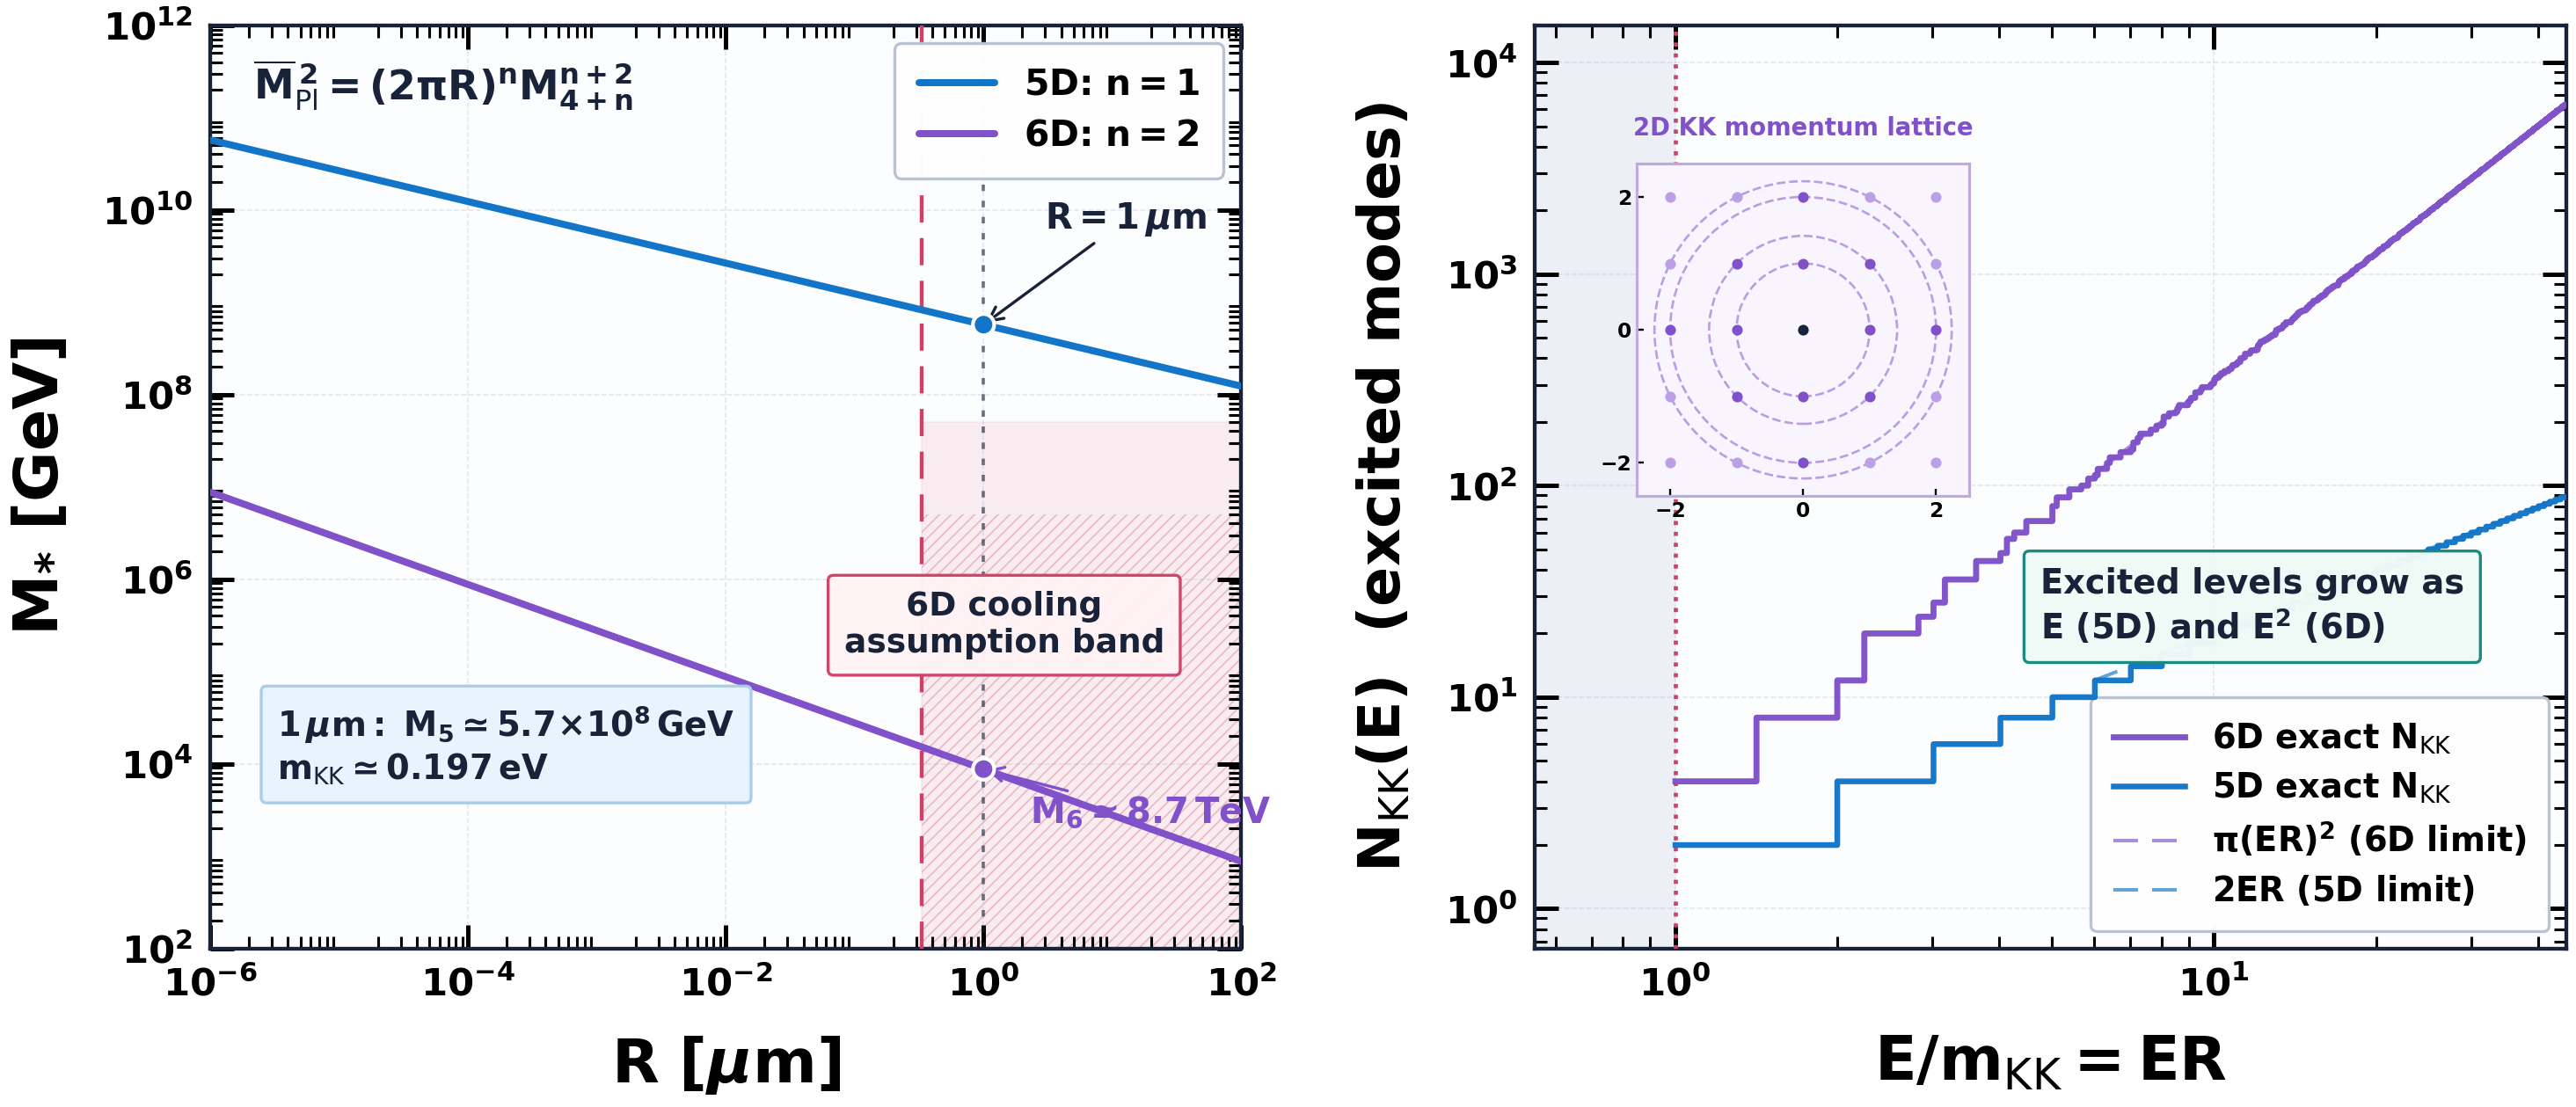

R = 1 um:  M5 = 5.710e+08 GeV,  M6 = 8.745e+03 GeV,  m_KK = 0.197 eV
Conditional 6D cooling interpretation:  R <~ 0.329 um for m_KK >~ 0.6 eV
Figure saved to D:\Dark-Dimension_projects\DarkDim-Universe_Reveiw\DD_Review_All_Figures


In [3]:
# %% [markdown]
# Reproducible new Figure: compactification scale and KK-state multiplicities.
# This cell is standalone; paste into the review notebook.
# Convention: Mbar_Pl^2=(2*pi*R)^n * M_D^(n+2) for a flat equal-radius torus.
# Physical KK gap m_KK=1/R, and 5D/6D exact mode counting includes ± momentum vectors.
# SN1987A cooling figure is conditional on assumptions in Hardy, Sokolov & Stubbs,
# JHEP 03 (2026) 029, arXiv:2510.18975.

from pathlib import Path
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, LogLocator, NullFormatter, FuncFormatter
from matplotlib.patches import Circle

# Use notebook-local output directory from the setup cell
OUT.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# Colors and typography — enlarged bold publication settings
# ---------------------------------------------------------------------------
INK = '#182238'
MUTED = '#56627A'
BLUE = '#1375C8'
VIOLET = '#8051C9'
RED = '#CF4267'
GOLD = '#CE872F'
TEAL = '#17887E'
SOFT_BLUE = '#E9F3FD'
SOFT_LAVENDER = '#F3EDFC'

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'mathtext.fontset': 'dejavusans',
    'mathtext.default': 'bf',
    'figure.dpi': 120,
    'savefig.facecolor': 'white',
})

def bold_decade(value, _pos):
    if value <= 0:
        return ''
    power = np.log10(value)
    rounded = int(np.rint(power))
    if not np.isclose(power, rounded, atol=1.e-7):
        return ''
    return rf'$\mathbf{{10}}^{{\mathbf{{{rounded}}}}}$'

def style_log(ax, xdecades=None, ydecades=None):
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_facecolor('#FCFDFF')
    if xdecades is not None:
        ax.xaxis.set_major_locator(FixedLocator(10.0 ** np.array(xdecades, dtype=float)))
    if ydecades is not None:
        ax.yaxis.set_major_locator(FixedLocator(10.0 ** np.array(ydecades, dtype=float)))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(FuncFormatter(bold_decade))
        axis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10), numticks=120))
        axis.set_minor_formatter(NullFormatter())
    ax.tick_params(axis='both', which='major', direction='in',
                   top=True, right=True, length=16, width=3.0, labelsize=26, pad=12)
    ax.tick_params(axis='both', which='minor', direction='in',
                   top=True, right=True, length=8.5, width=1.85)
    for label in ax.get_xticklabels()+ax.get_yticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(26)
    for spine in ax.spines.values():
        spine.set_color(INK)
        spine.set_linewidth(2.6)
    ax.grid(which='major', color='#98ABC1', ls='--', lw=.95, alpha=.27)
    ax.set_axisbelow(True)

def bold_legend(ax, loc, fs=22.0):
    leg = ax.legend(loc=loc, fontsize=fs, frameon=True, fancybox=True,
                    framealpha=.98, facecolor='white', edgecolor='#B8C2D1',
                    labelspacing=.44, borderpad=.68, handlelength=2.1)
    leg.get_frame().set_linewidth(2.0)
    for label in leg.get_texts():
        label.set_weight('bold')
    return leg

def note(ax, x, y, s, ec=BLUE, fc='white', fs=23, ha='left'):
    return ax.text(x,y,s,transform=ax.transAxes,ha=ha,va='center',
                   fontsize=fs,fontweight='bold',color=INK,
                   bbox={'boxstyle':'round,pad=.48,rounding_size=.16',
                         'ec':ec,'fc':fc,'lw':2.0,'alpha':.98}, zorder=25)

# ---------------------------------------------------------------------------
# EXACT (flat equal-radius torus) 5D and 6D scales
# ---------------------------------------------------------------------------
MPL_REDUCED_GEV = 2.435e18
METER_TO_GEV_INV = 5.067730716e15
R_um = np.geomspace(1e-6, 1e2, 801)
R_invgev = R_um * 1.e-6 * METER_TO_GEV_INV

def MD_torus(n, radius_GeVinv):
    return (MPL_REDUCED_GEV**2 / (2*np.pi*radius_GeVinv)**n)**(1/(n+2))

M5_GeV = MD_torus(1, R_invgev)
M6_GeV = MD_torus(2, R_invgev)
KKgap_eV = 1e9/R_invgev
R1 = 1.e-6*METER_TO_GEV_INV
M5_1 = float(MD_torus(1,R1))
M6_1 = float(MD_torus(2,R1))
mKK1 = 1e9/R1

# For n=2, conditional SN1987A limit m_KK >~ 0.6 eV.
# Mapping m_KK=1/R to an R bound is convention-dependent.
MKK_COOLING_EV = 0.6
R_COOLING_UM = 0.1973269804/MKK_COOLING_EV

# ---------------------------------------------------------------------------
# EXACT excited KK state counting with mass |k|/R; zero mode excluded.
# ---------------------------------------------------------------------------
u = np.linspace(0.55,44.8,2350)
N5 = 2 * np.floor(u).astype(int)
kmax = int(np.ceil(u.max()))
ki, kj = np.meshgrid(np.arange(-kmax,kmax+1),
                     np.arange(-kmax,kmax+1), indexing='ij')
magnitudes = np.sort(np.hypot(ki.ravel(),kj.ravel()))
N6 = np.searchsorted(magnitudes,u,side='right')-1
u_asym = np.geomspace(6,45,200)

# ---------------------------------------------------------------------------
# Two-panel figure with a small 2D lattice inset
# ---------------------------------------------------------------------------
fig, (ax, ay) = plt.subplots(1,2,figsize=(24.5,10.8))
fig.patch.set_facecolor('white')
fig.subplots_adjust(left=.076,right=.987,bottom=.145,top=.955,wspace=.285)

# LEFT: R vs fundamental gravitational scale
ax.set(xlim=(1e-6,1e2), ylim=(1e2,1e12))
style_log(ax, [-6,-4,-2,0,2], [2,4,6,8,10,12])

# Conditional cooling-shaded region applies to six-dimensional line only
ax.fill_between(R_um, 1e2, 5e7,
                where=(R_um>=R_COOLING_UM), color=RED, alpha=.085, zorder=0)
ax.axvspan(R_COOLING_UM,1e2,ymin=0,ymax=.47,
           facecolor='none', hatch='///', edgecolor='#E8B8C5',lw=0,zorder=0)
ax.axvline(R_COOLING_UM,color=RED,lw=2.65,ls=(0,(7,4)),zorder=4)
ax.axvline(1.0,color=INK,lw=2.2,ls=(0,(2,3)),alpha=.62)

ax.plot(R_um,M5_GeV,color=BLUE,lw=4.8,solid_capstyle='round',label=r'5D: $n=1$',zorder=6)
ax.plot(R_um,M6_GeV,color=VIOLET,lw=4.8,solid_capstyle='round',label=r'6D: $n=2$',zorder=6)
ax.scatter([1,1],[M5_1,M6_1],s=[210,210],color=[BLUE,VIOLET],
           linewidths=2.5,edgecolors='white',zorder=9)

ax.annotate(r'$\mathbf{R}=\mathbf{1}\,\boldsymbol{\mu}\mathbf{m}$',
            xy=(1,M5_1),xytext=(3.0,6.2e9),
            color=INK,fontsize=24,fontweight='bold',
            arrowprops={'arrowstyle':'->','color':INK,'lw':2.0})
ax.annotate(r'$\mathbf{M}_{\mathbf{6}}\simeq\mathbf{8.7}\,\mathbf{TeV}$',
            xy=(1,M6_1),xytext=(2.3,2.3e3),
            color=VIOLET,fontsize=24,fontweight='bold',
            arrowprops={'arrowstyle':'->','color':VIOLET,'lw':2.0})

ax.text(.042,.964,r'$\overline{M}_{\rm Pl}^{\,2}=(2\pi R)^nM_{4+n}^{n+2}$',
        transform=ax.transAxes,va='top',fontsize=27.5,fontweight='bold',color=INK)

note(ax,.065,.22,
     r'$\mathbf{1}\,\boldsymbol{\mu}\mathbf{m}:\ \mathbf{M}_{\mathbf{5}}\simeq\mathbf{5.7}\!\times\!\mathbf{10}^{\mathbf{8}}\,\mathbf{GeV}$'
     '\n'+r'$\mathbf{m}_{\rm KK}\simeq\mathbf{0.197}\,\mathbf{eV}$',
     ec='#A9CDE8',fc=SOFT_BLUE,fs=23)
note(ax,.77,.35,'6D cooling\nassumption band',ec=RED,fc='#FFF3F5',fs=22.5,ha='center')
ax.set_xlabel(r'$\mathbf{R}\ [\boldsymbol{\mu}\mathbf{m}]$',fontsize=42,fontweight='bold',labelpad=21)
ax.set_ylabel(r'$\mathbf{M}_{\boldsymbol{*}}\ [\mathbf{GeV}]$',fontsize=42,fontweight='bold',labelpad=22)
bold_legend(ax,'upper right',24.5)

# RIGHT: exact spectrum vs asymptotic state growth
ay.set(xlim=(.55,45),ylim=(.65,1.5e4))
style_log(ay, None, [0,1,2,3,4])
ay.xaxis.set_major_locator(FixedLocator([1,10]))
ay.axvspan(.55,1,fc='#EBEFF5',alpha=.9,zorder=0)
ay.axvline(1,color=RED,ls=':',lw=2.8,zorder=4)

# Discrete exact counts and continuum large-ER approximation
ay.step(u,np.where(N6>0,N6,np.nan),where='post',lw=4.1,
        color=VIOLET,alpha=.98,label=r'6D exact $N_{\rm KK}$',zorder=6)
ay.step(u,np.where(N5>0,N5,np.nan),where='post',lw=3.9,
        color=BLUE,alpha=.98,label=r'5D exact $N_{\rm KK}$',zorder=7)
ay.plot(u_asym,np.pi*u_asym**2,ls=(0,(7,4)),lw=2.4,
        color=VIOLET,alpha=.66,label=r'$\pi(ER)^2$ (6D limit)',zorder=5)
ay.plot(u_asym,2*u_asym,ls=(0,(7,4)),lw=2.4,
        color=BLUE,alpha=.66,label=r'$2ER$ (5D limit)',zorder=5)

# Display the integer lattice momenta defining 6D KK states.
# Top-left region is free of count curves for u <~ 2.
inset = ay.inset_axes([.07,.49,.38,.36])
inset.set_facecolor('#F8F5FF')
for rr in [1, np.sqrt(2), 2, np.sqrt(5)]:
    inset.add_patch(Circle((0,0),rr,fill=False,edgecolor=VIOLET,lw=1.6,ls='--',alpha=.52))
for kx in range(-2,3):
    for ky in range(-2,3):
        if kx==0 and ky==0:
            facecolor=INK
        else:
            facecolor=VIOLET if (kx*kx+ky*ky<=4) else '#BBA0E7'
        inset.plot(kx,ky,'o',color=facecolor,ms=6.3)
inset.set(xlim=(-2.5,2.5),ylim=(-2.5,2.5),aspect='equal')
inset.set_xticks([-2,0,2]);inset.set_yticks([-2,0,2])
inset.tick_params(labelsize=14,axis='both',direction='in',length=5,width=1.4)
for tick in inset.get_xticklabels() + inset.get_yticklabels():
    tick.set_fontweight('bold')
for spine in inset.spines.values():spine.set_color('#BFAADB');spine.set_linewidth(1.9)
inset.text(.5,1.07,'2D KK momentum lattice',ha='center',va='bottom',
           fontsize=16.5,fontweight='bold',color=VIOLET,transform=inset.transAxes)

note(ay,.49,.37,'Excited levels grow as\n$E$ (5D) and $E^2$ (6D)',
     ec=TEAL,fc='#EFFAF7',fs=23)

ay.set_xlabel(r'$\mathbf{E}/\mathbf{m}_{\rm KK}=\mathbf{E}\mathbf{R}$',
              fontsize=42,fontweight='bold',labelpad=21)
ay.set_ylabel(r'$\mathbf{N}_{\rm KK}(\mathbf{E})$  (excited modes)',
              fontsize=40,fontweight='bold',labelpad=22)
bold_legend(ay,'lower right',23.0)

# ---------------------------------------------------------------------------
# Save figures and data; display directly in Jupyter
# ---------------------------------------------------------------------------
fig.savefig(OUT/'Fig2_Compactification_KK.png',dpi=210,bbox_inches='tight',facecolor='white')
fig.savefig(OUT/'Fig2_Compactification_KK.pdf',bbox_inches='tight',facecolor='white')
np.savetxt(OUT/'data/Fig2_Compactification_5D_6D.dat',
           np.column_stack([R_um,M5_GeV,M6_GeV,KKgap_eV]),
           header='R_um M5_GeV M6_GeV mKK_eV')
np.savetxt(OUT/'data/Fig2_KK_Exact_Mode_Counts.dat',
           np.column_stack([u,N5,N6]),
           header='E_over_mKK N_KK_5D_excited N_KK_6D_excited',fmt=['%.10e','%d','%d'])
display(fig)
plt.close(fig)
print(f'R = 1 um:  M5 = {M5_1:.3e} GeV,  M6 = {M6_1:.3e} GeV,  m_KK = {mKK1:.3f} eV')
print(f'Conditional 6D cooling interpretation:  R <~ {R_COOLING_UM:.3f} um for m_KK >~ 0.6 eV')
print('Figure saved to',OUT.resolve())

## Draft Figure 3 — Higher-dimensional horizon, temperature, and spin

The upper two panels use the Schwarzschild–Tangherlini horizon and Hawking temperature:

$$
r_H^{D-3}=\frac{16\pi G_D M}{(D-2)\Omega_{D-2}},\qquad
\Omega_{D-2}=\frac{2\pi^{(D-1)/2}}{\Gamma[(D-1)/2]},\qquad
T_H=\frac{D-3}{4\pi r_H}.
$$

For a singly spinning Myers–Perry black hole in $D=4+n$ dimensions at **fixed mass**, with $a_*=a/r_H$,

$$
\frac{r_H(a_*)}{r_S}=(1+a_*^2)^{-1/(n+1)},\qquad
\frac{T_H(a_*)}{T_H(0)}=
\frac{n+1+(n-1)a_*^2}{(n+1)(1+a_*^2)^{n/(n+1)}}.
$$

Dotted sections in the upper panels indicate where the chosen local higher-dimensional, semiclassical approximation fails the plotted checks; they are not a physical continuation of a complete compactified solution.

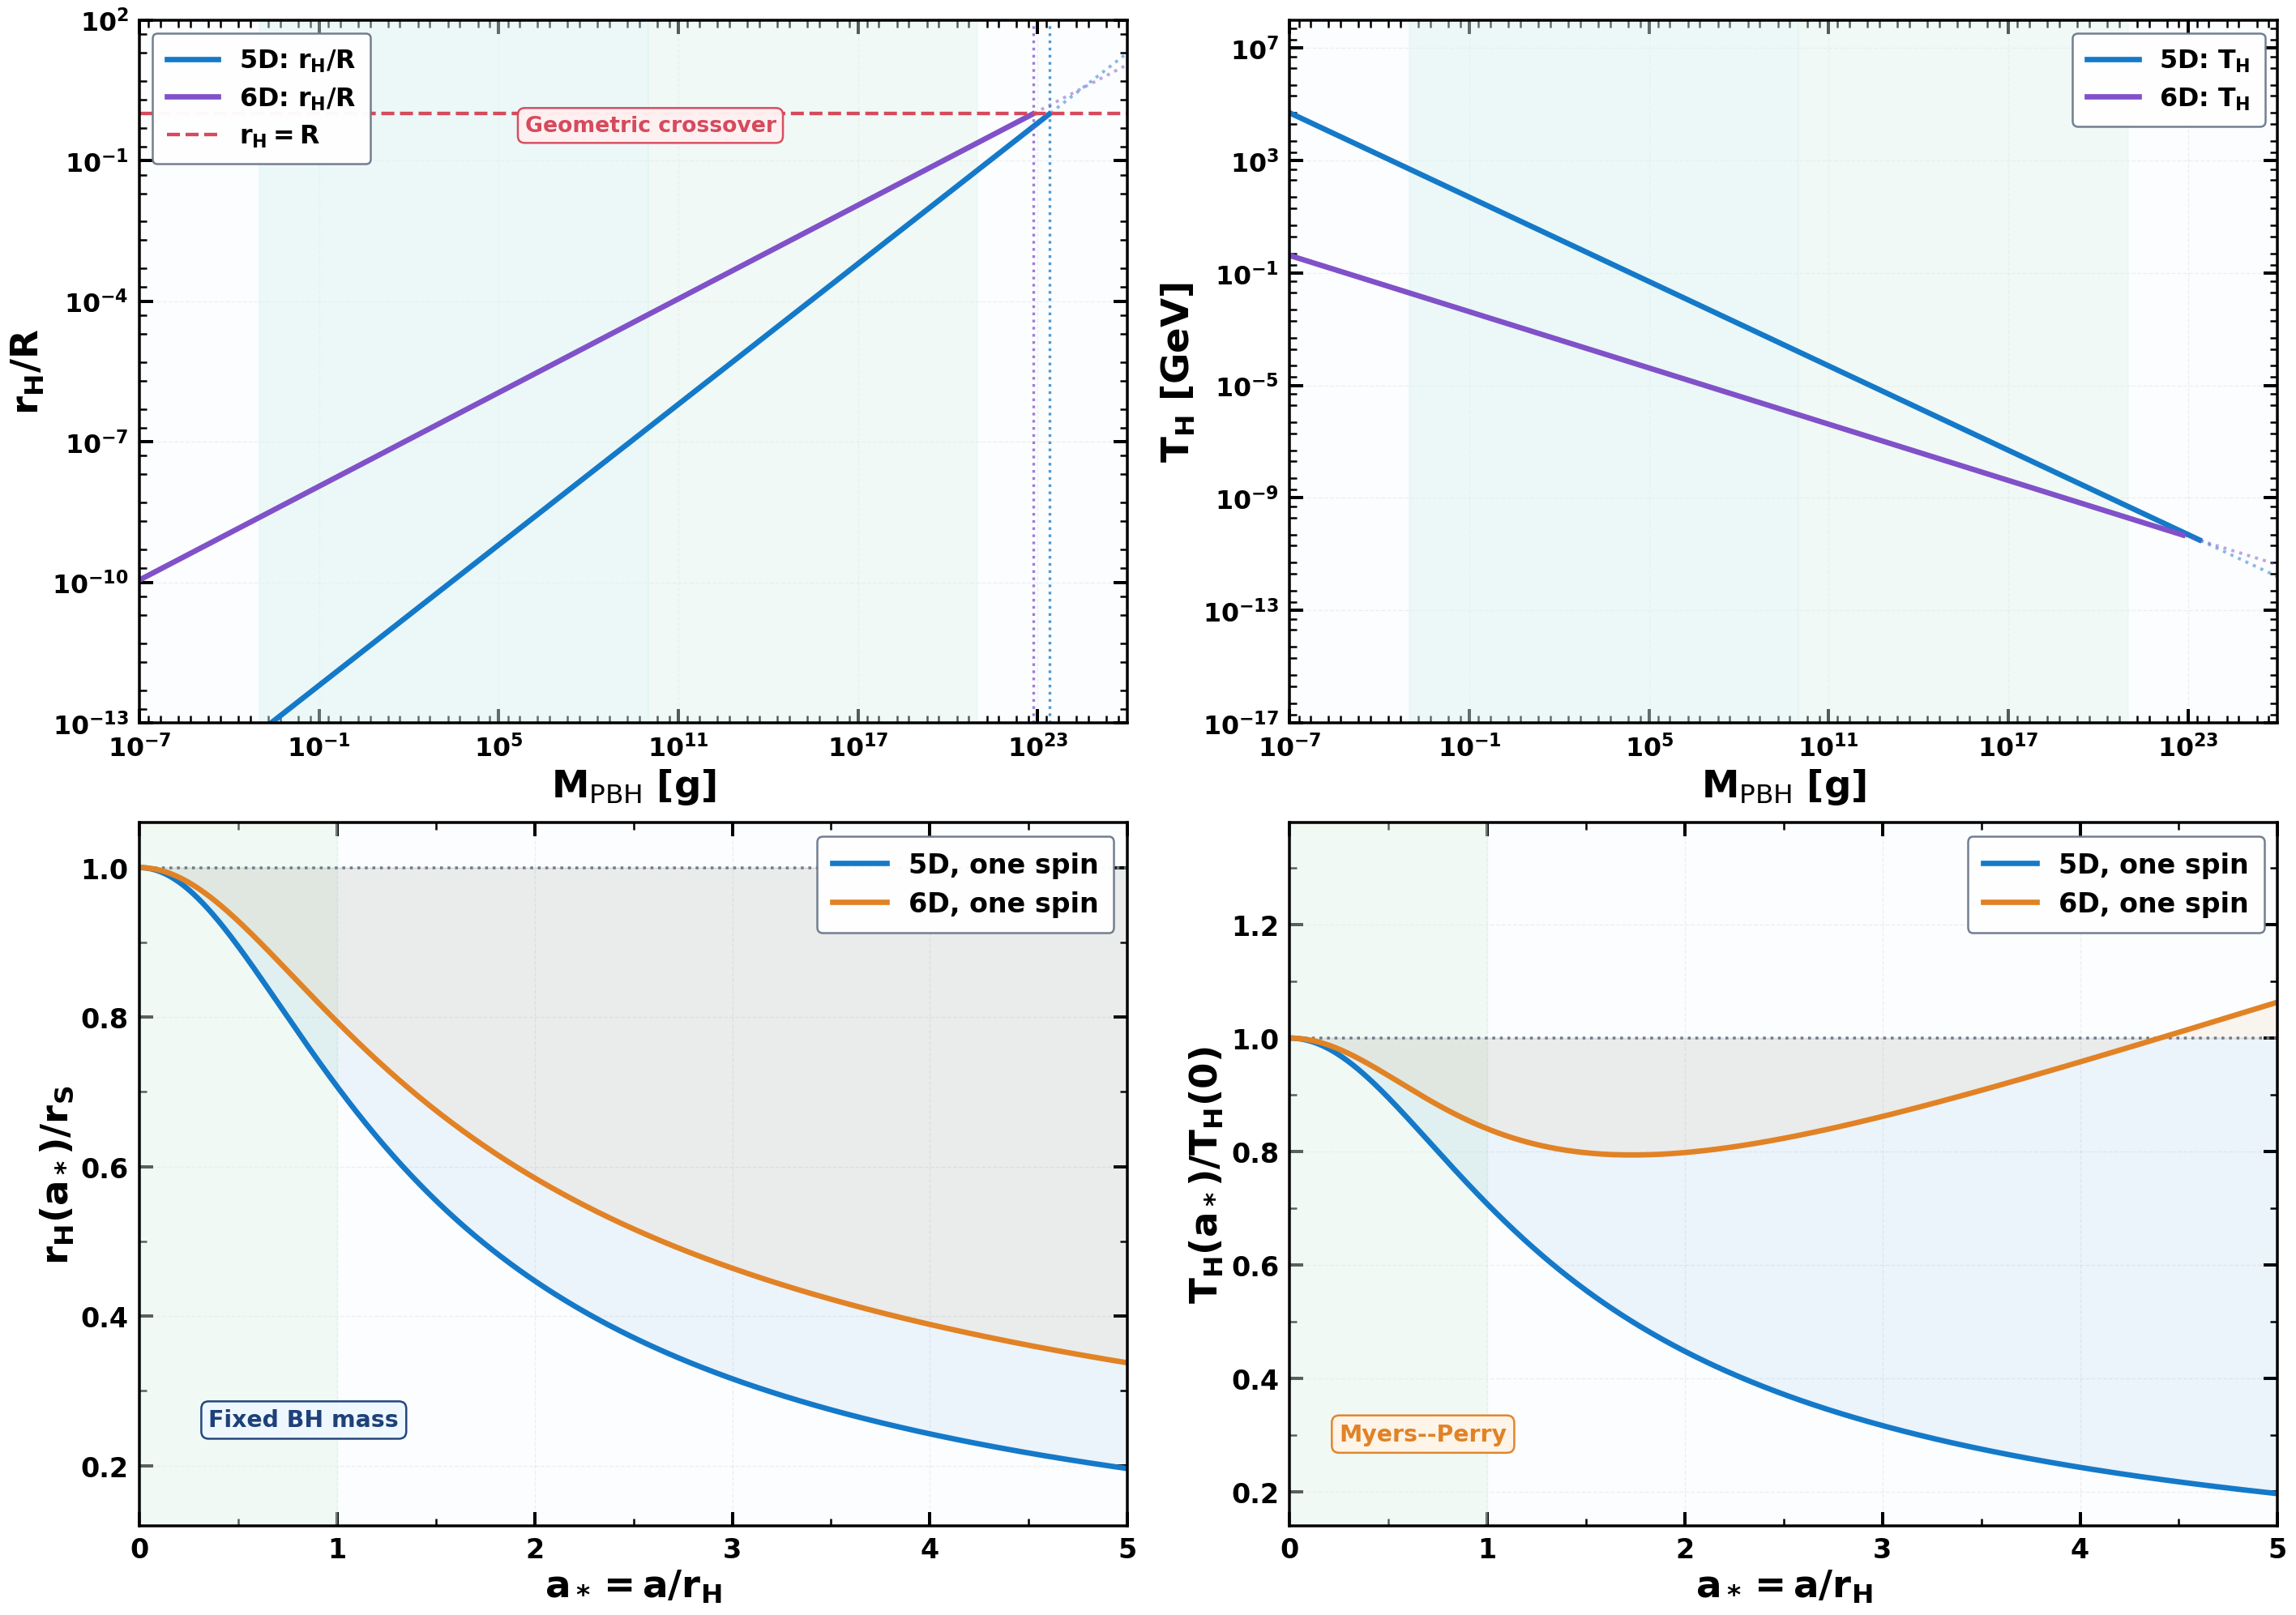

Saved: Fig3_Horizon_Temperature_Rotation.pdf / .png


In [4]:
# ============== FIGURE 3: FOUR PHYSICALLY COMPUTED PANELS ==============
fig,axs=plt.subplots(2,2,figsize=(23.5,16.5),constrained_layout=True)
a,b,c,d=axs.flatten()
m=np.geomspace(1e-7,1e26,720)
for ax in [a,b]:
    ax.axvspan(1e-3,1e10,color=PASTEL['teal'],alpha=.45)
    ax.axvspan(1e10,1e21,color=PASTEL['green'],alpha=.38)
for D,col in [(5,'blue'),(6,'purple')]:
    ratio=r_h(m,D)/R_GEV
    valid=(ratio<1)&(m*G_TO_GEV>1e3*MD_dim(D))
    a.plot(m,np.where(valid,ratio,np.nan),color=C[col],lw=4,label=f'{D}D: $r_H/R$')
    a.plot(m,np.where(~valid,ratio,np.nan),color=C[col],lw=2.3,ls=':',alpha=.5)
    tt=T_h(m,D)
    b.plot(m,np.where(valid,tt,np.nan),color=C[col],lw=4,label=f'{D}D: $T_H$')
    b.plot(m,np.where(~valid,tt,np.nan),color=C[col],lw=2.3,ls=':',alpha=.5)
    a.axvline(cross_mass_g(D),color=C[col],ls=':',lw=2,alpha=.75)
a.axhline(1,color=C['red'],ls='--',lw=2.6,label=r'$r_H=R$')
a.set(xlim=(1e-7,1e26),ylim=(1e-13,1e2))
b.set(xlim=(1e-7,1e26),ylim=(1e-17,1e8))
a.set_xlabel(r'$\mathbf{M}_{\rm PBH}\ [\mathbf{g}]$')
b.set_xlabel(r'$\mathbf{M}_{\rm PBH}\ [\mathbf{g}]$')
a.set_ylabel(r'$\mathbf{r}_H/\mathbf{R}$')
b.set_ylabel(r'$\mathbf{T}_H\ [\mathbf{GeV}]$')
for ax,exp in [(a,[-13,-10,-7,-4,-1,2]),(b,[-17,-13,-9,-5,-1,3,7])]:
    style(ax,True,True,label=28,ticks=19,xexp=[-7,-1,5,11,17,23],yexp=exp)
legend(a,'upper left',fs=19)
legend(b,'upper right',fs=19)
box(a,'Geometric crossover',.39,.85,'red',16,fc='#FFF0F1')

spin=np.linspace(0,5,550)
for ax in [c,d]:
    ax.axvspan(0,1,color=PASTEL['green'],alpha=.4)
    ax.axhline(1,color=C['gray'],ls=':',lw=2.1)
for D,col in [(5,'blue'),(6,'orange')]:
    n=D-4
    rr=(1+spin**2)**(-1/(n+1))
    th=(n+1+(n-1)*spin**2)/((n+1)*(1+spin**2)**(n/(n+1)))
    c.plot(spin,rr,lw=4,color=C[col],label=f'{D}D, one spin')
    c.fill_between(spin,rr,1,color=C[col],alpha=.07)
    d.plot(spin,th,lw=4,color=C[col],label=f'{D}D, one spin')
    d.fill_between(spin,th,1,color=C[col],alpha=.07)
c.set(xlim=(0,5),ylim=(.12,1.06));d.set(xlim=(0,5),ylim=(.14,1.38))
c.set_xlabel(r'$\mathbf{a}_*=\mathbf{a}/\mathbf{r}_H$')
d.set_xlabel(r'$\mathbf{a}_*=\mathbf{a}/\mathbf{r}_H$')
c.set_ylabel(r'$\mathbf{r}_H(\mathbf{a}_*)/\mathbf{r}_S$')
d.set_ylabel(r'$\mathbf{T}_H(\mathbf{a}_*)/\mathbf{T}_H(0)$')
for ax in [c,d]:style(ax,label=28,ticks=20)
legend(c,'upper right',fs=20)
legend(d,'upper right',fs=20)
box(c,'Fixed BH mass',.07,.15,'navy',17,fc='#EFF7FF')
box(d,'Myers--Perry',.05,.13,'orange',17,fc='#FFF4E8')
save_show(fig,'Fig3_Horizon_Temperature_Rotation',dpi=210)
np.savetxt(DATA/'Fig3_Horizon_Temperature_5D6D.dat',
           np.column_stack([m,r_h(m,5)/R_GEV,r_h(m,6)/R_GEV,T_h(m,5),T_h(m,6)]),
           header='mass_g rH_over_R_5D rH_over_R_6D TH_GeV_5D TH_GeV_6D')

## Draft Figure 4 — Log-normal primordial spectra and Gaussian PBH formation

A log-normal enhancement of primordial curvature power is parametrized by

$$
\mathcal P_{\mathcal R}(k)=
\frac{\mathcal A_{\mathcal R}}{\sqrt{2\pi}\,\Delta}
\exp\!\left[-\frac{\ln^2(k/k_*)}{2\Delta^2}\right],
\qquad k_*(M)=7\times10^{13}\left(\frac{10^{18}\,\mathrm g}{M}\right)^{1/2}\mathrm{Mpc}^{-1}.
$$

The five example peaks reproduce the **mass ordering and functional form** of the supplied spectrum. They are **calculated from the stated log-normal Ansatz**, not digitized from the original image. The colored vertical backgrounds only identify approximate wavenumber domains often discussed by CMB distortions and PTA studies; they are **not reconstructed observational exclusion curves**.

For the right-hand panel the deliberately simplified Gaussian-tail estimate is

$$
\beta\simeq\frac12\operatorname{erfc}\left(\frac{\delta_c}{\sqrt2\,\sigma_\delta}\right),
\qquad \sigma_\delta\simeq\frac49\sqrt{\mathcal P_{\mathcal R}(k_*)}.
$$

A precision abundance calculation requires the smoothing/window and transfer functions, critical collapse, and any non-Gaussianity. The benchmark is **not** a directly measured $f_{\rm PBH}$ constraint.

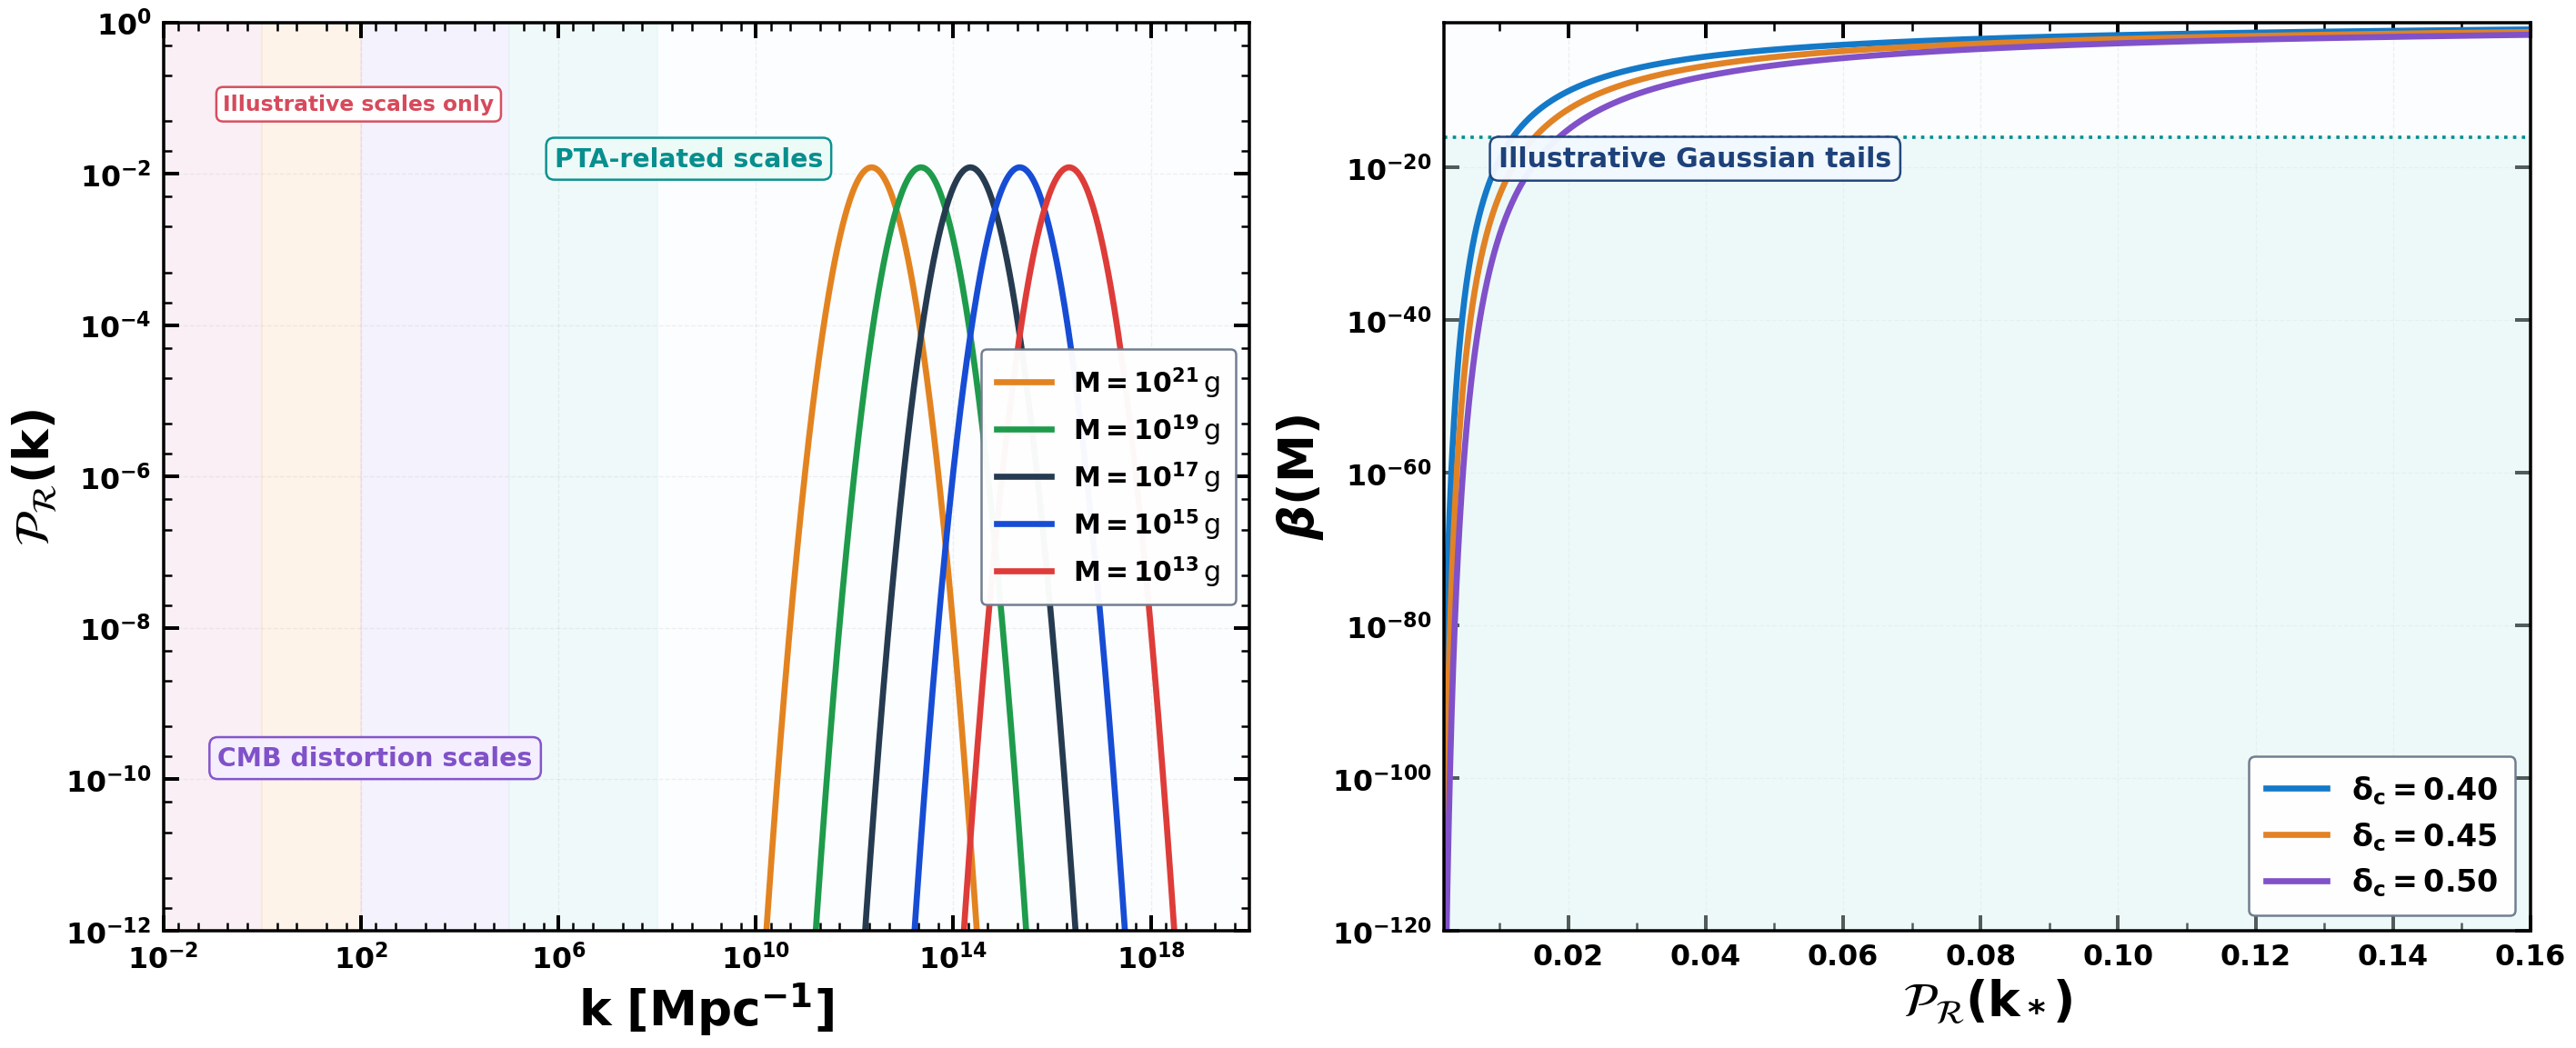

Saved: Fig4_Curvature_Formation.pdf / .png


In [5]:
# ============== FIGURE 4: Five log-normal peaks + Gaussian collapse ==============
M_PEAKS=[1e21,1e19,1e17,1e15,1e13]
PEAK_COLORS=['#E38320','#1E9B4B','#263B50','#174DD5','#DE3C39']
ks=np.geomspace(1e-2,1e20,1300)
peak_p=np.geomspace(.002,.16,650)
def PR(k,kpeak,A=A_PR,Delta=WIDTH):
    return A/(np.sqrt(2*np.pi)*Delta)*np.exp(-.5*(np.log(np.asarray(k)/kpeak)/Delta)**2)

fig,(ax,ay)=plt.subplots(1,2,figsize=(23.5,9.5),constrained_layout=True)
for lo,hi,cc in [(1e-2,1,'rose'),(1,1e2,'orange'),(1e2,1e5,'purple'),
                 (1e5,1e8,'teal')]:
    ax.axvspan(lo,hi,color=PASTEL[cc],alpha=.35,zorder=0)
for mass,col in zip(M_PEAKS,PEAK_COLORS):
    yy=PR(ks,peak_k(mass))
    ax.plot(ks,yy,color=col,lw=4.0,
            label=fr'$M=10^{{{int(round(np.log10(mass)))}}}\,\mathrm{{g}}$')
    np.savetxt(DATA/f'Fig4_PR_M1e{int(round(np.log10(mass)))}g.dat',
               np.column_stack([ks,yy]),header='k_Mpc^-1 curvature_power_P_R')
ax.set(xlim=(1e-2,1e20),ylim=(1e-12,1))
ax.set_xlabel(r'$\mathbf{k}\ [\mathbf{Mpc}^{-1}]$')
ax.set_ylabel(r'$\mathcal{P}_{\mathcal{R}}(\mathbf{k})$')
style(ax,True,True,label=32,ticks=19,
      xexp=[-2,2,6,10,14,18],yexp=[-12,-10,-8,-6,-4,-2,0])
legend(ax,'center right',fs=18)
box(ax,'CMB distortion scales',.05,.19,'purple',17,fc='#F5EEFF')
box(ax,'PTA-related scales',.36,.85,'teal',17,fc='#EDFBF7')
box(ax,'Illustrative scales only',.055,.91,'red',14,fc='white')

ay.axhspan(1e-120,1e-16,color=PASTEL['teal'],alpha=.38)
for delta,col in [(.40,'blue'),(.45,'orange'),(.50,'purple')]:
    sigma=(4/9)*np.sqrt(peak_p)
    beta=np.exp(log_ndtr(-delta/sigma))
    ay.plot(peak_p,beta,color=C[col],lw=4,label=fr'$\delta_c={delta:.2f}$')
    np.savetxt(DATA/f'Fig4_Beta_delta_{delta:.2f}.dat',
               np.column_stack([peak_p,beta]),header='P_R_peak Gaussian_beta')
ay.axhline(1e-16,color=C['teal'],ls=':',lw=2.2)
ay.set(xlim=(.002,.16),ylim=(1e-120,1e-1))
ay.set_xlabel(r'$\mathcal{P}_{\mathcal{R}}(\mathbf{k}_*)$')
ay.set_ylabel(r'$\boldsymbol{\beta}(\mathbf{M})$')
style(ay,False,True,label=32,ticks=19,yexp=[-120,-100,-80,-60,-40,-20,0])
legend(ay,'lower right',fs=20)
box(ay,'Illustrative Gaussian tails',.05,.85,'navy',18,fc='#F2F8FF')
save_show(fig,'Fig4_Curvature_Formation',dpi=220)

## Draft Figure 5 — Scalar-induced gravitational waves and instrument comparison

In radiation domination, the time-averaged tensor energy density induced at second order by Gaussian scalar perturbations is an integral over two scalar wavevectors:

$$
\Omega_{\rm GW}(\eta,k)=\frac{1}{24}\left(\frac{k}{\mathcal H}\right)^2
\overline{\mathcal P_h(\eta,k)},\qquad
\mathcal P_h(k)\propto\int_0^\infty\!dv\int_{|1-v|}^{1+v}\!du\,
\mathcal K(u,v)\mathcal P_{\mathcal R}(ku)\mathcal P_{\mathcal R}(kv).
$$

The notebook evaluates a radiation-era convolution kernel numerically for the **massless four-dimensional tensor zero mode**. The supplied shape is converted to a present-day illustrative $\Omega_{\rm GW,0}h^2$. Detector noise-equivalent curves are calculated from analytic instrumental PSD fits and **are not cross-correlated SGWB upper limits**. The NANOGrav point is an illustrative conversion of a reported characteristic strain at $f=1/{\rm yr}$, not an exclusion.

To check numerical stability, the kernel is computed on two grids below. The integration uses whichever of `numpy.trapezoid` or `numpy.trapz` exists, for compatibility with older Anaconda installations.

In [6]:
import numpy as np

# NumPy >=2: trapezoid; older Anaconda NumPy: trapz.
# Both perform the same composite trapezoidal quadrature.
trap_integral = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz

# ============================================================
# Stable radiation-era scalar convolution kernel
# t = u + v - 1, s = u - v
# ============================================================

def kernel_table(nt=450, ns=130):

    tr = np.sqrt(3) - 1

    focus = np.r_[
        tr - np.geomspace(.26, 1e-8, 95),
        tr + np.geomspace(1e-8, .26, 95)
    ]

    tt = np.unique(
        np.sort(
            np.r_[
                np.linspace(1e-4, 4, nt),
                np.geomspace(4.01, 45, 60),
                focus
            ]
        )
    )

    ss = np.linspace(-.9995, .9995, ns)

    t = tt[:, None]
    s = ss[None, :]

    u = (1 + t + s) / 2
    v = (1 + t - s) / 2

    q = u*u + v*v - 3

    geom = (
        4*v*v - (1 + v*v - u*u)**2
    ) / (4*u*v)

    ratio = np.maximum(
        np.abs(
            (3 - (u + v)**2) /
            (3 - (u - v)**2)
        ),
        1e-14
    )

    term = (
        (-4*u*v + q*np.log(ratio))**2
        + np.pi**2*q*q*(u + v >= np.sqrt(3))
    )

    K = (
        geom**2
        * (3*q / (4*u**3*v**3))**2
        * term
    )

    return tt, ss, u, v, np.nan_to_num(
        K, nan=0, posinf=0, neginf=0
    )


# ============================================================
# Precompute kernel
# ============================================================

TT, SS, UU, VV, KER = kernel_table()


# ============================================================
# Log-normal primordial curvature spectrum
# ============================================================

def PR_ratio(z, A=.022, Delta=.72):

    zz = np.maximum(np.asarray(z), 1e-250)

    return (
        A / (np.sqrt(2*np.pi)*Delta)
        * np.exp(
            -0.5*(np.log(zz)/Delta)**2
        )
    )


# ============================================================
# Scalar-induced gravitational-wave spectrum
# Compatible with older NumPy versions
# ============================================================

def sigw_shape(x, A=.022, Delta=.72, table=None):

    if table is None:
        table = (TT, SS, UU, VV, KER)

    tt, ss, u, v, ker = table

    out = []

    for z in np.atleast_1d(x):

        integrand = (
            0.5 * ker
            * PR_ratio(z*u, A, Delta)
            * PR_ratio(z*v, A, Delta)
        )

        # FIX: np.trapz replaces np.trapezoid
        integral_s = trap_integral(
            integrand, x=ss, axis=1
        )

        integral_t = trap_integral(
            integral_s, x=tt
        )

        out.append(integral_t / 12)

    return 1.62e-5 * np.asarray(out)


# ============================================================
# Numerical calculation
# ============================================================

xx = np.geomspace(.0018, 180, 140)

OMEGA = sigw_shape(
    xx,
    A=A_PR,
    Delta=WIDTH
)

assert (
    np.all(np.isfinite(OMEGA))
    and np.all(OMEGA > 0)
), "Invalid SIGW spectrum values"


# ============================================================
# Numerical convergence test
# ============================================================

coarse = sigw_shape(
    xx[::12],
    A=A_PR,
    Delta=WIDTH,
    table=kernel_table(360, 110)
)

err = np.max(
    np.abs(coarse - OMEGA[::12])
    / np.maximum(OMEGA[::12], 1e-100)
)

print(
    f"Coarse versus finer numerical-grid check: "
    f"maximum {err:.2%} for {len(coarse)} test frequencies"
)

print("SIGW computation completed successfully.")
print("NumPy version:", np.__version__)

Coarse versus finer numerical-grid check: maximum 0.26% for 12 test frequencies
SIGW computation completed successfully.
NumPy version: 1.26.4


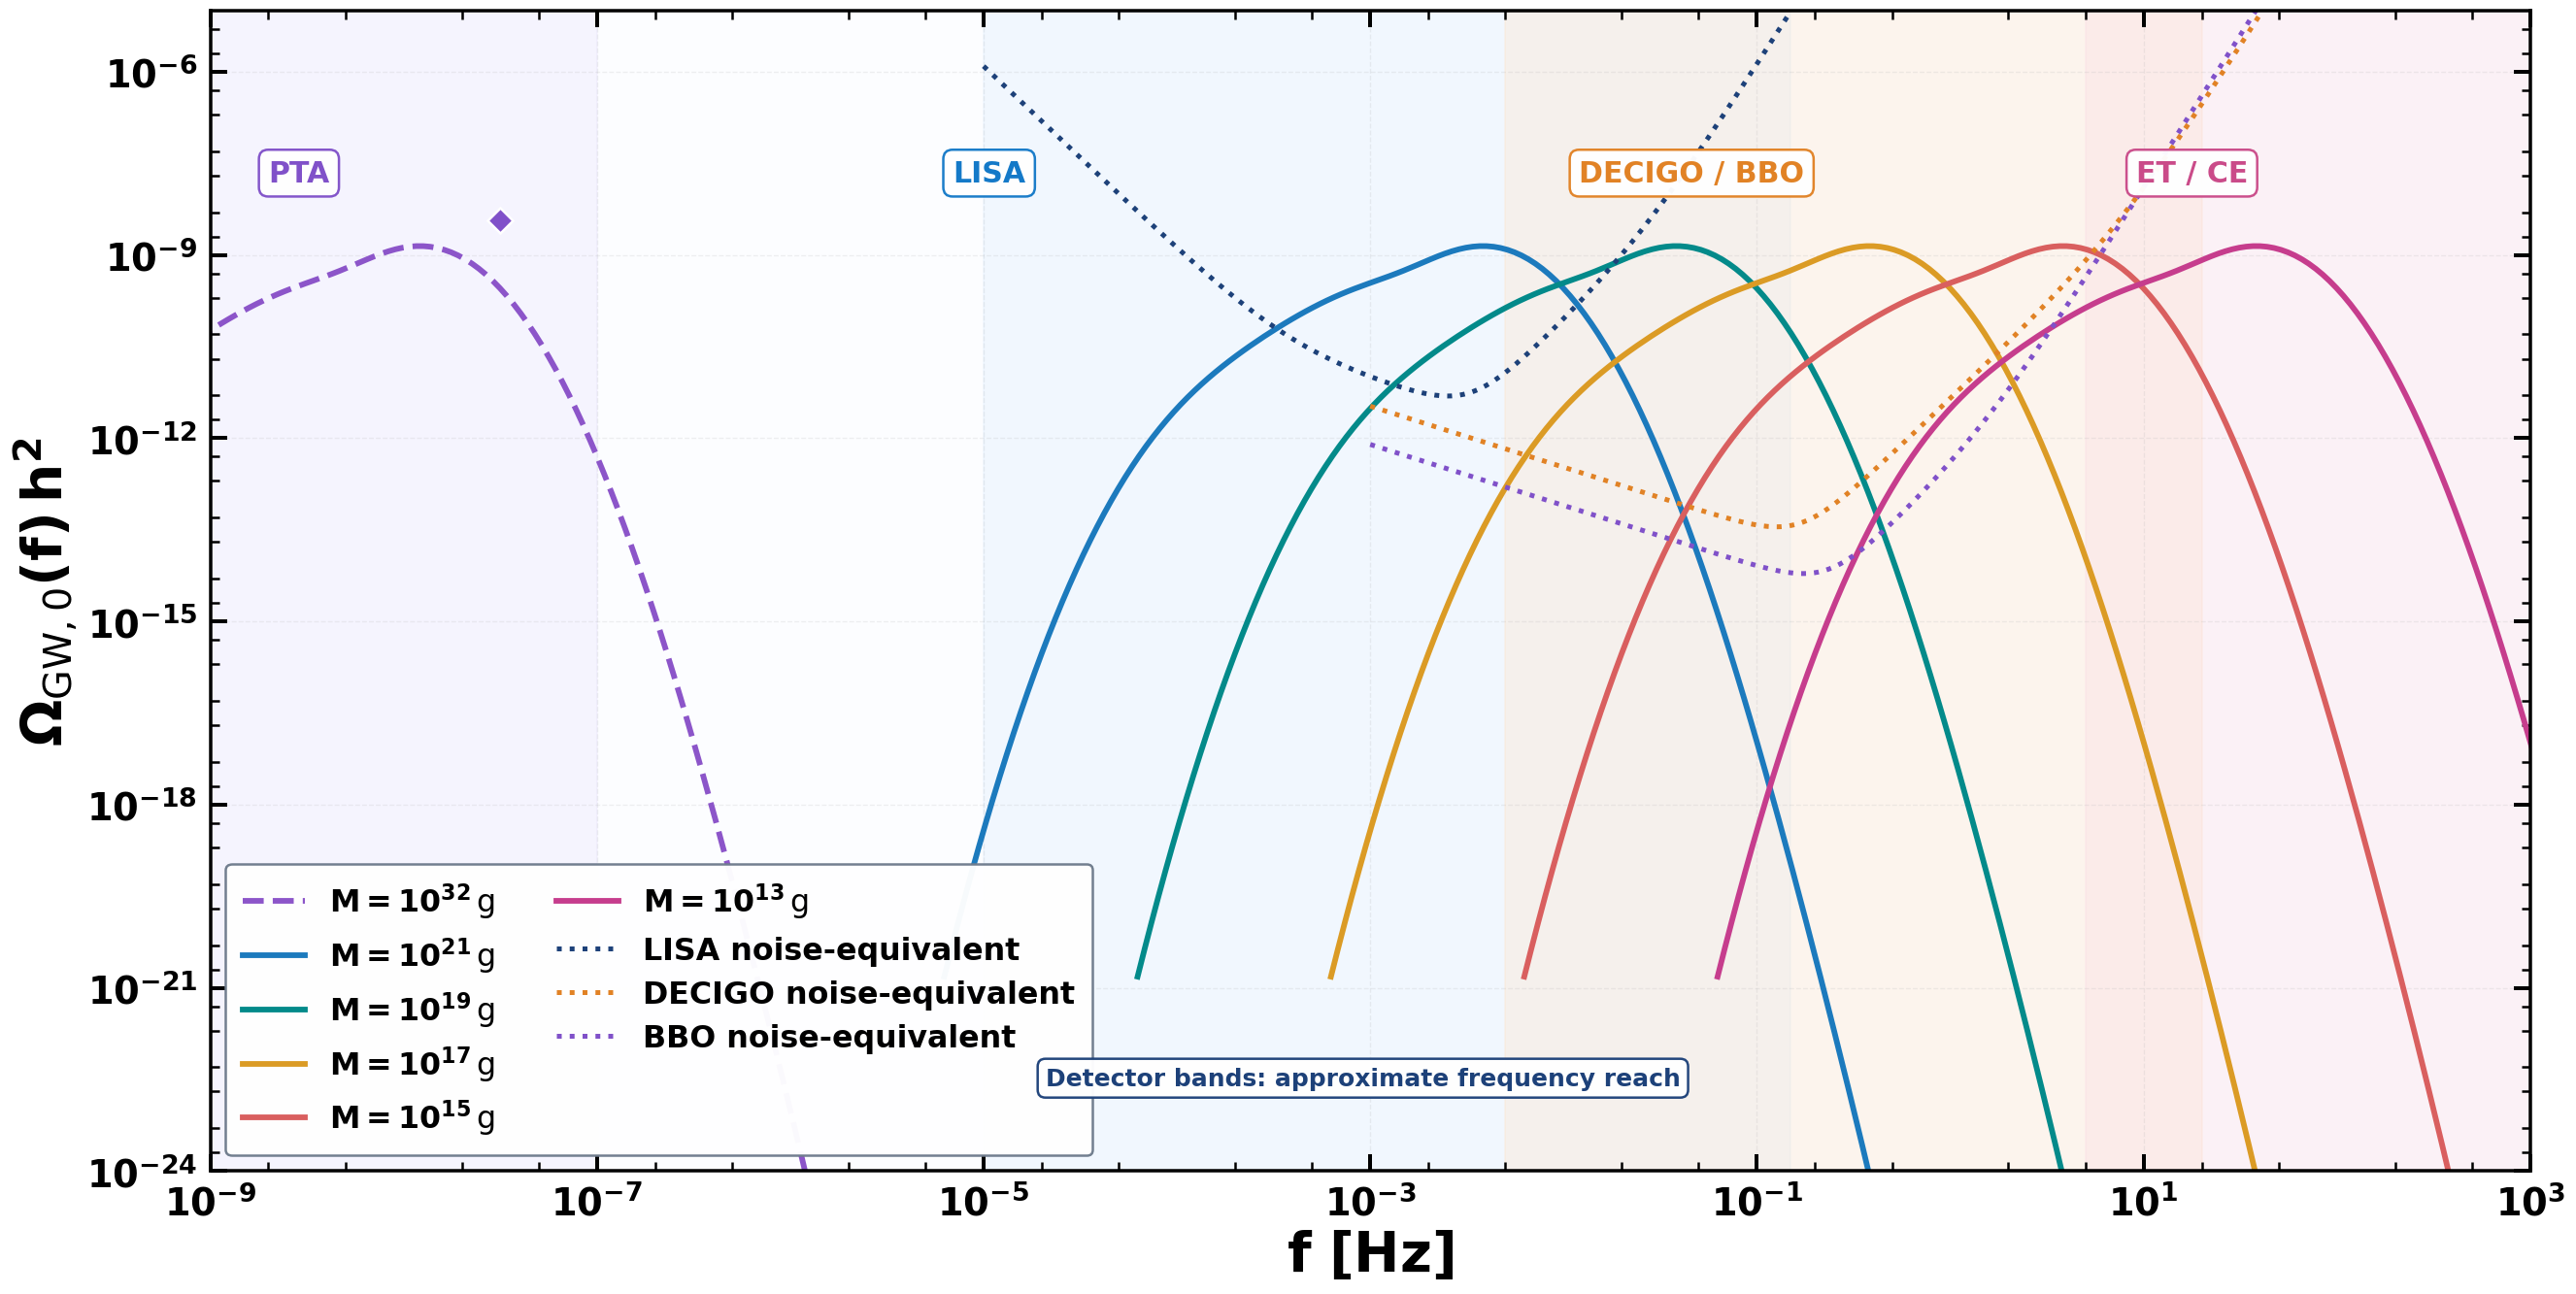

Saved: Fig5_SIGW_Detectors.pdf / .png


In [7]:
# ============== FIGURE 5: Numerical SIGW spectrum and noise equivalents ==============
H0=67.4*1000/3.085677581491367e22
h=.674

def Sn_LISA(f):
    f=np.asarray(f); L=2.5e9; fstar=299792458/(2*np.pi*L)
    Poms=(1.5e-11)**2*(1+(2e-3/f)**4)
    Pacc=(3e-15)**2*(1+(0.4e-3/f)**2)*(1+(f/8e-3)**4)
    return 10/(3*L**2)*(Poms+4*Pacc/(2*np.pi*f)**4)*(1+.6*(f/fstar)**2)

def Sn_DECIGO(f):
    f=np.asarray(f); fp=7.35
    return 7.05e-48*(1+(f/fp)**2)+4.8e-51*f**(-4)/(1+(f/fp)**2)+5.33e-52*f**(-4)

def Sn_BBO(f):
    f=np.asarray(f)
    return 2e-49*f**2+4.58e-49+1.26e-51*f**(-4)

def noise_omega(f,psd):
    return h*h*2*np.pi**2/(3*H0**2)*np.asarray(f)**3*psd(f)

fig,ax=plt.subplots(figsize=(22,11),constrained_layout=True)
for lo,hi,col in [(1e-9,1e-7,'purple'),(1e-5,.15,'blue'),(.005,20,'orange'),(5,1e3,'rose')]:
    ax.axvspan(lo,hi,color=PASTEL[col],alpha=.29,zorder=0)
GW_MASSES=[1e32,1e21,1e19,1e17,1e15,1e13]
GW_COLORS=['#8C55C9','#1C7ABD','#038A8A','#DB9B25','#D95F5F','#C63D8D']
for mass,col in zip(GW_MASSES,GW_COLORS):
    ff=peak_f(mass)*xx
    lab=fr'$M=10^{{{int(round(np.log10(mass)))}}}\,\mathrm{{g}}$'
    ax.loglog(ff,OMEGA,lw=3.5,color=col,ls='--' if mass>1e27 else '-',
              label=lab)
    np.savetxt(DATA/f'Fig5_SIGW_M1e{int(round(np.log10(mass)))}g.dat',
               np.column_stack([ff,OMEGA]),header='frequency_Hz Omega_GW_h2')
for name,psd,col,lo,hi in [('LISA',Sn_LISA,'navy',1e-5,.5),
                            ('DECIGO',Sn_DECIGO,'orange',1e-3,40),
                            ('BBO',Sn_BBO,'purple',1e-3,40)]:
    ff=np.geomspace(lo,hi,480)
    yy=noise_omega(ff,psd)
    ax.loglog(ff,yy,lw=3,ls=':',color=C[col],label=name+' noise-equivalent')
    np.savetxt(DATA/f'Fig5_Noise_{name}.dat',np.column_stack([ff,yy]),
               header='frequency_Hz Omega_noise_equivalent_h2')

# Illustrative NANOGrav strain conversion at f=1/year.
fyr=1/YEAR_S
hc=2.4e-15
H100=100*1000/3.085677581491367e22
ng=(2*np.pi**2/(3*H100**2))*fyr**2*hc**2
ax.plot(fyr,ng,'D',color=C['purple'],ms=11,mec='white',mew=1.5,zorder=10)
np.savetxt(DATA/'Fig5_NANOGrav_illustrative.dat',np.array([[fyr,ng]]),
           header='frequency_Hz Omega_GW_h2_illustrative_strain_conversion')
ax.set(xlim=(1e-9,1e3),ylim=(1e-24,1e-5))
ax.set_xlabel(r'$\mathbf{f}\ [\mathbf{Hz}]$')
ax.set_ylabel(r'$\boldsymbol{\Omega}_{\rm GW,0}(\mathbf{f})\,\mathbf{h}^2$')
style(ax,True,True,label=34,ticks=23,
      xexp=[-9,-7,-5,-3,-1,1,3],yexp=[-24,-21,-18,-15,-12,-9,-6])
legend(ax,'lower left',fs=19,ncol=2)
for lab,x,co in [('PTA',.025,'purple'),('LISA',.32,'blue'),
                 ('DECIGO / BBO',.59,'orange'),('ET / CE',.83,'rose')]:
    box(ax,lab,x,.86,co,18,fc='white')
box(ax,'Detector bands: approximate frequency reach',.36,.08,'navy',15,fc='white')
save_show(fig,'Fig5_SIGW_Detectors',dpi=220)

## Draft Figure 6 — LISA, DECIGO and BBO Fisher-covariance corner diagrams

For a parameter vector

$$
\boldsymbol\theta=
\left(\log_{10}\frac{M}{\mathrm g},\log_{10}\mathcal A_{\mathcal R},\Delta\right),
$$

an intentionally simplified diagonal-frequency covariance gives

$$
F_{ij}\simeq T_{\rm obs}
\int_{f_{\rm min}}^{f_{\rm max}}\!
\frac{\partial_i\Omega_{\rm GW}(f)\,\partial_j\Omega_{\rm GW}(f)}
{[\Omega_{\rm n}(f)+\Omega_{\rm GW}(f)]^2}\,df,
\qquad\mathrm{Cov}(\theta_i,\theta_j)=(F^{-1})_{ij}.
$$

The Fisher matrices are recalculated here from the **numerical SIGW kernel**, then converted to 68.3% and 95.4% 2D Gaussian ellipses. They are toy projections, **not official mission likelihoods** and **not constraints on the memory exponent** $p$.

In [8]:
# Interpolate numerical spectra in log frequency; preserve amplitude^2 scaling.
D_FID=WIDTH; DSTEP=.06
shape0=sigw_shape(xx,A=1,Delta=D_FID)
shapeP=sigw_shape(xx,A=1,Delta=D_FID+DSTEP)
shapeM=sigw_shape(xx,A=1,Delta=D_FID-DSTEP)
LNX=np.log(xx)
I0=PchipInterpolator(LNX,np.log(np.maximum(shape0,1e-200)),extrapolate=False)
IP=PchipInterpolator(LNX,np.log(np.maximum(shapeP,1e-200)),extrapolate=False)
IM=PchipInterpolator(LNX,np.log(np.maximum(shapeM,1e-200)),extrapolate=False)

def omega_theta(freq,th):
    logmass,logamp,width=th
    xi=np.log(np.asarray(freq)/peak_f(10**logmass))
    lnshape=I0(xi)
    slope=np.nan_to_num((IP(xi)-IM(xi))/(2*DSTEP),nan=0)
    return np.nan_to_num(np.exp(lnshape+(width-D_FID)*slope)*10**(2*logamp),
                         nan=0,posinf=0,neginf=0)

def compute_fisher(det,theta,T_years=4):
    bands={'LISA':(3e-5,.25,Sn_LISA),'DECIGO':(.003,15,Sn_DECIGO),
           'BBO':(.003,15,Sn_BBO)}
    lo,hi,psd=bands[det]
    f=np.geomspace(lo,hi,470)
    sig=omega_theta(f,theta)
    ns=noise_omega(f,psd)
    deriv=[]
    for i,step in enumerate([.004,.006,.035]):
        plus=theta.copy(); minus=theta.copy()
        plus[i]+=step;minus[i]-=step
        deriv.append((omega_theta(f,plus)-omega_theta(f,minus))/(2*step))
    deriv=np.asarray(deriv)
    # This is a transparent toy likelihood, not a full cross-correlated data analysis.
    ww=T_years*YEAR_S/(ns+sig)**2
    F=np.array([[trap_integral(ww*deriv[i]*deriv[j],f) for j in range(3)] for i in range(3)])
    eig=np.linalg.eigvalsh(F)
    if eig.min()<=0:raise ValueError(f'{det}: singular Fisher matrix: {eig}')
    COV=np.linalg.inv(F)
    return COV,F

FIDS={'LISA':np.array([21.,np.log10(A_PR),D_FID]),
      'DECIGO':np.array([18.,np.log10(A_PR),D_FID]),
      'BBO':np.array([18.,np.log10(A_PR),D_FID])}
FISH={}
for det in FIDS:
    cov,fmat=compute_fisher(det,FIDS[det]); FISH[det]=(cov,fmat)
    print(det,'illustrative 1sigma:',dict(zip(['log10 M','log10 A','width'],np.sqrt(np.diag(cov)).round(5))))

LISA illustrative 1sigma: {'log10 M': 0.00061, 'log10 A': 0.0003, 'width': 0.00075}
DECIGO illustrative 1sigma: {'log10 M': 8e-05, 'log10 A': 4e-05, 'width': 4e-05}
BBO illustrative 1sigma: {'log10 M': 7e-05, 'log10 A': 4e-05, 'width': 3e-05}


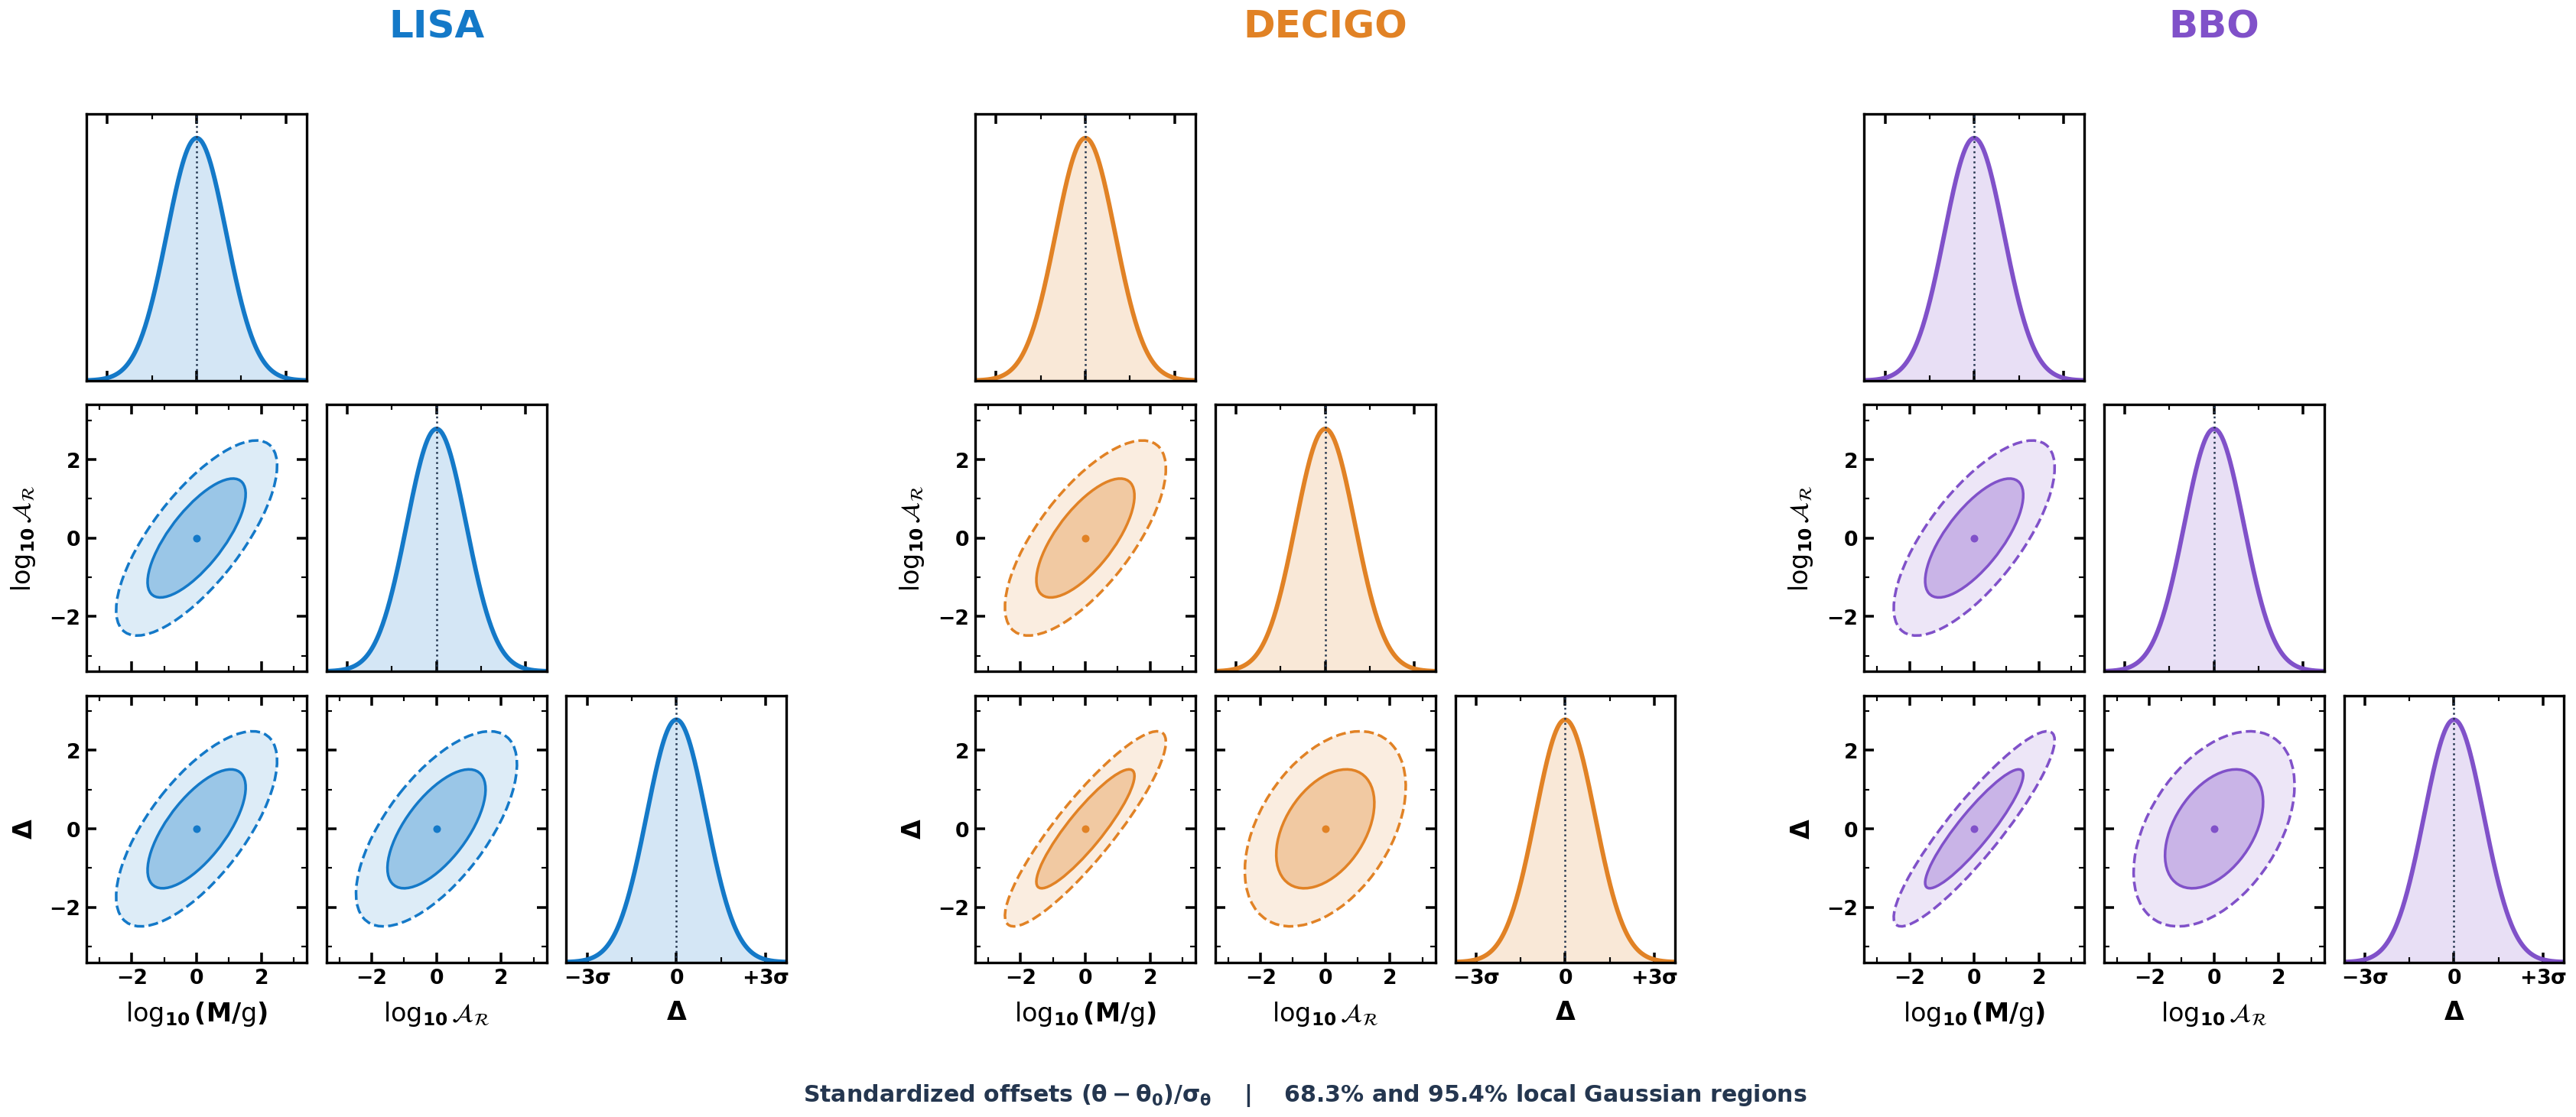

Saved: Fig6_Fisher_Corners.pdf / .png


In [9]:
# ============== FIGURE 6: Recomputed Fisher corner plots ==============
labels=[r'$\log_{10}(M/\mathrm{g})$',r'$\log_{10}\mathcal{A}_{\mathcal{R}}$',r'$\Delta$']
names=['LISA','DECIGO','BBO']
cols=[C['blue'],C['orange'],C['purple']]
fig=plt.figure(figsize=(29.5,13.5))
outer=fig.add_gridspec(1,3,left=.07,right=.985,bottom=.18,top=.865,wspace=.27)
for idx,(name,color) in enumerate(zip(names,cols)):
    cov=FISH[name][0]
    sigma=np.sqrt(np.diag(cov))
    inner=outer[idx].subgridspec(3,3,wspace=.09,hspace=.09)
    for i in range(3):
        for j in range(3):
            ax=fig.add_subplot(inner[i,j])
            if i<j:
                ax.axis('off');continue
            if i==j:
                z=np.linspace(-3.8,3.8,280)
                density=np.exp(-.5*z*z)
                ax.plot(z,density,color=color,lw=3.5)
                ax.fill_between(z,0,density,color=color,alpha=.18)
                ax.axvline(0,color=C['dark'],ls=':',lw=1.5)
                ax.set(xlim=(-3.7,3.7),ylim=(0,1.1))
                ax.set_yticks([])
                ax.set_xticks([-3,0,3])
                ax.set_xticklabels([r'$-3\sigma$',r'$0$',r'$+3\sigma$'])
            else:
                corr=cov[np.ix_([j,i],[j,i])]/np.outer([sigma[j],sigma[i]],[sigma[j],sigma[i]])
                eig,vec=np.linalg.eigh(corr)
                angle=np.degrees(np.arctan2(vec[1,1],vec[0,1]))
                for conf,alpha,ls in [(.9545,.14,'--'),(.6827,.33,'-')]:
                    factor=np.sqrt(chi2.ppf(conf,2))
                    w,hg=2*factor*np.sqrt(eig[1]),2*factor*np.sqrt(eig[0])
                    ax.add_patch(Ellipse((0,0),w,hg,angle=angle,facecolor=color,alpha=alpha))
                    ax.add_patch(Ellipse((0,0),w,hg,angle=angle,facecolor='none',edgecolor=color,lw=2.1,ls=ls))
                ax.plot(0,0,'o',color=color,ms=5)
                ax.set(xlim=(-3.4,3.4),ylim=(-3.4,3.4))
                ax.set_xticks([-2,0,2]);ax.set_yticks([-2,0,2])
                if j>0:ax.set_yticklabels([])
            if i<2:ax.set_xticklabels([])
            if i==2:ax.set_xlabel(labels[j],fontsize=20,fontweight='bold',labelpad=9)
            if j==0 and i>0:ax.set_ylabel(labels[i],fontsize=20,fontweight='bold',labelpad=9)
            ax.tick_params(which='major',direction='in',top=True,right=True,
                           labelsize=16,width=2.1,length=8,pad=5)
            ax.tick_params(which='minor',direction='in',top=True,right=True,width=1.3,length=4)
            ax.xaxis.set_minor_locator(AutoMinorLocator(2))
            if i!=j:ax.yaxis.set_minor_locator(AutoMinorLocator(2))
            for t in ax.get_xticklabels()+ax.get_yticklabels(): t.set_weight('bold')
            for spine in ax.spines.values():spine.set_linewidth(2.0)
    bbox=outer[idx].get_position(fig)
    fig.text((bbox.x0+bbox.x1)/2,.935,name,ha='center',va='center',
             fontsize=30,fontweight='bold',color=color)
fig.text(.52,.068,
         r'Standardized offsets $(\theta-\theta_0)/\sigma_\theta$    |    68.3% and 95.4% local Gaussian regions',
         ha='center',fontsize=18,fontweight='bold',color=C['dark'])
save_show(fig,'Fig6_Fisher_Corners',dpi=170)
for name in names:
    np.savetxt(DATA/f'Fig6_Fisher_Covariance_{name}.dat',FISH[name][0],
               header='Toy Fisher covariance for (log10(M/g),log10(A_R),Delta)')

## Supplemental Figure A — Gravitational-force crossover

The KK tower corrects the long-distance Newtonian interaction. For a source with unit relative overlap with the KK modes of a flat torus, a schematic force enhancement is

$$
\frac{F_n(r)}{F_{4\rm D}(r)}=
\sum_{\boldsymbol\ell\in\mathbb Z^n}
\left(1+\frac{r}{R}\lVert\boldsymbol\ell\rVert\right)
\exp\!\left[-\frac{r}{R}\lVert\boldsymbol\ell\rVert\right].
$$

It approaches the usual four-dimensional inverse-square law at $r\gg R$ and the $D=4+n$ short-distance power law at $r\ll R$. The force enhancement assumes the stated mode couplings and is therefore **illustrative**, not a universal radion-dependent force prediction.

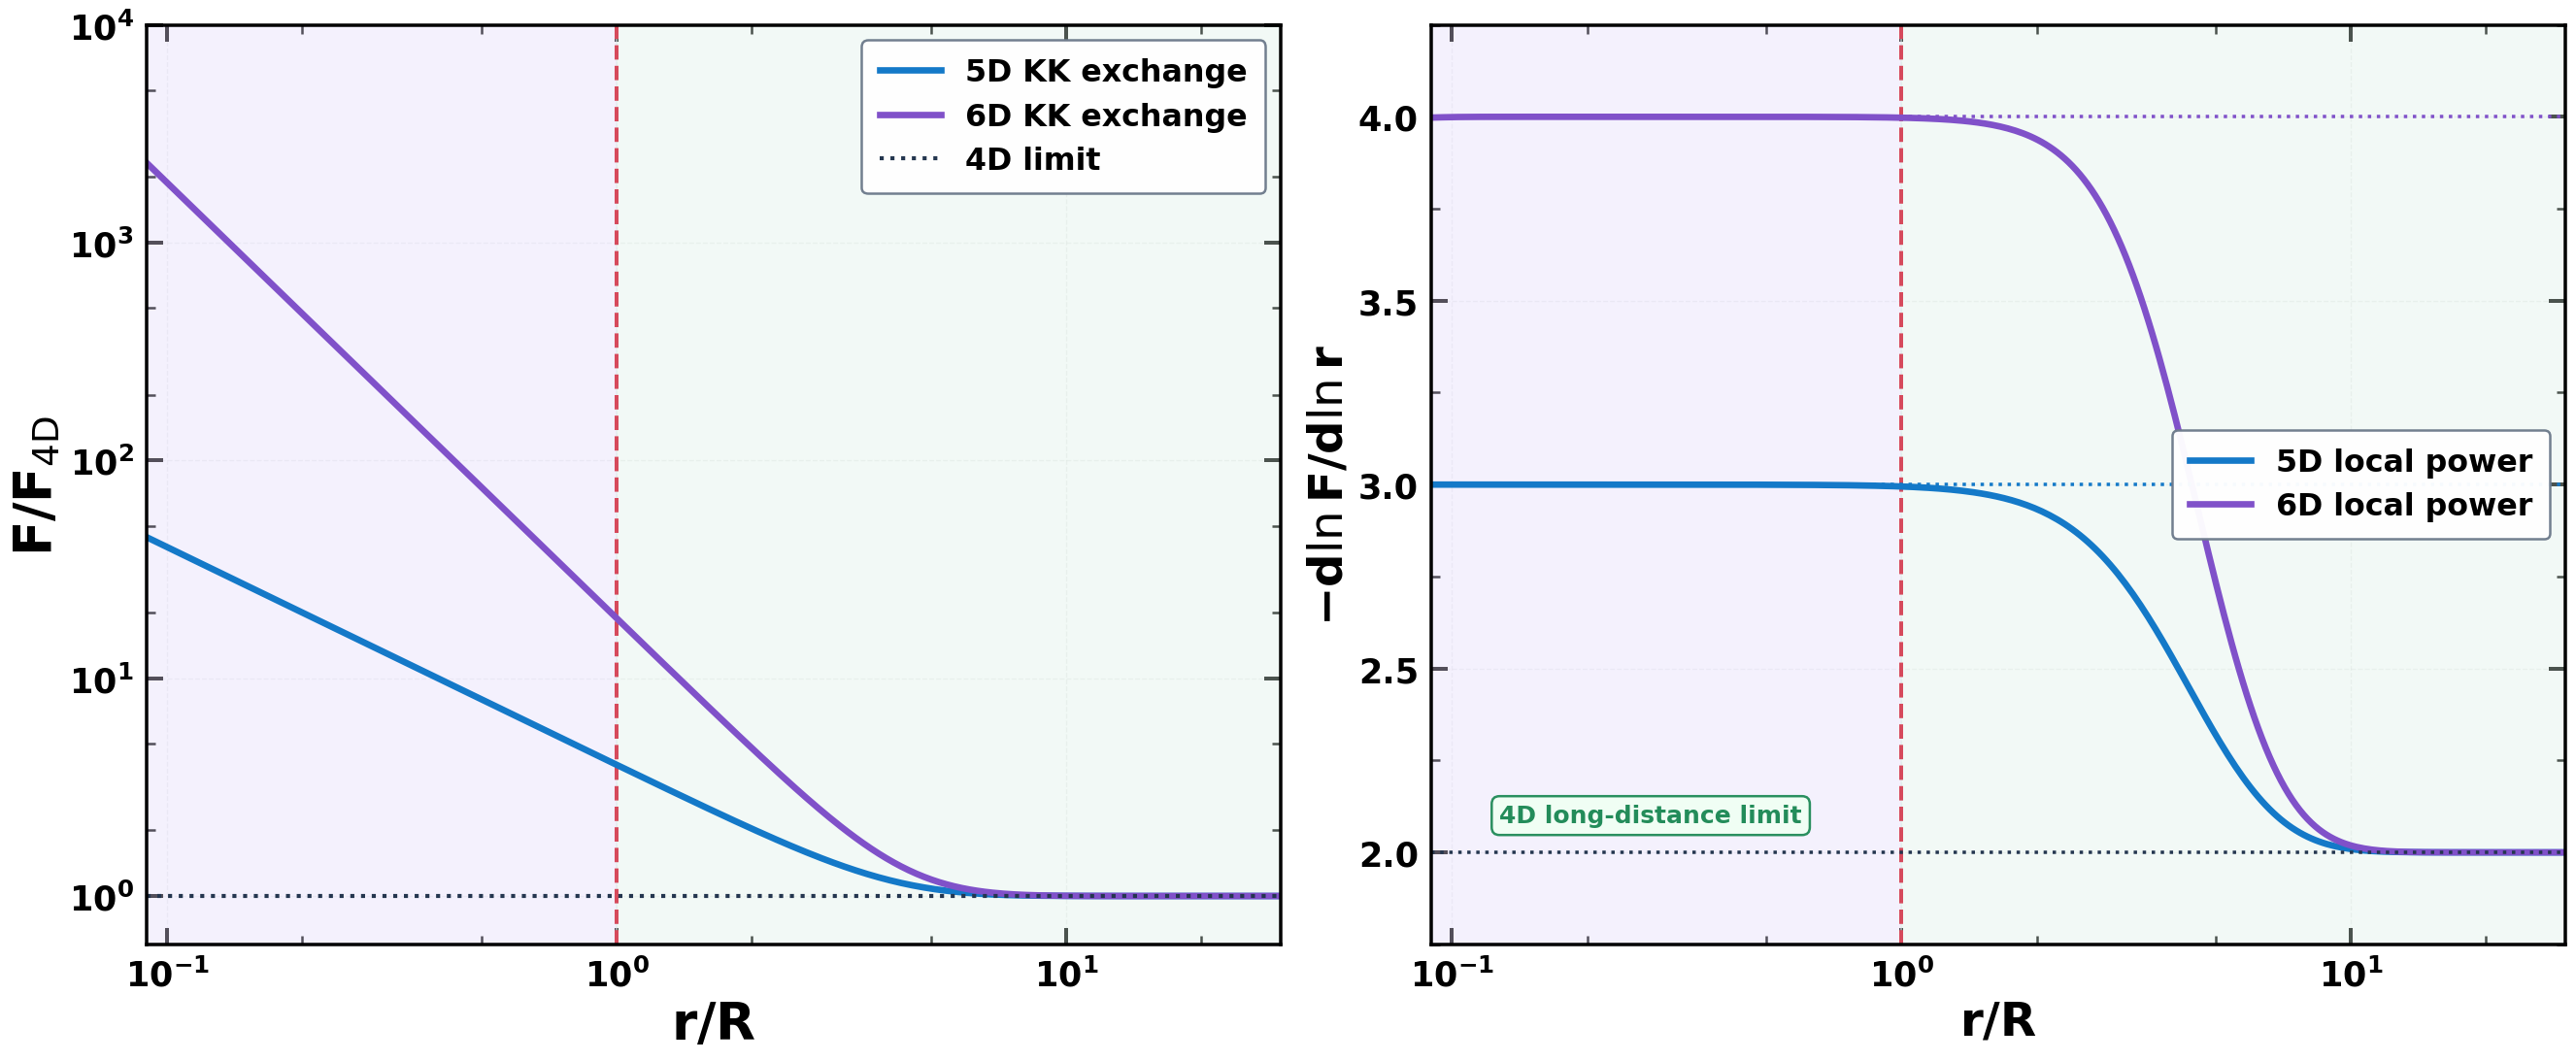

Saved: Supplement_A_Gravity_Crossover.pdf / .png


In [10]:
# ============== SUPPLEMENT A: KK exchange and gravity crossover ==============
rr=np.geomspace(.09,30,300)
y5=rr/2
F5=np.cosh(y5)/np.sinh(y5)+y5/np.sinh(y5)**2
v=np.arange(-130,131)
nsq=(v[:,None]**2+v[None,:]**2).ravel()
shell=np.bincount(nsq)
indices=np.flatnonzero(shell)[1:]
radii=np.sqrt(indices)
weights=shell[indices]
F6=np.empty_like(rr)
for i,x in enumerate(rr):
    z=x*radii
    F6[i]=1+np.sum(weights*(1+z)*np.exp(-z))
slope5=2-np.gradient(np.log(F5),np.log(rr))
slope6=2-np.gradient(np.log(F6),np.log(rr))
fig,(ax,ay)=plt.subplots(1,2,figsize=(22,9),constrained_layout=True)
for a in [ax,ay]:
    a.axvspan(rr.min(),1,color=PASTEL['purple'],alpha=.36)
    a.axvspan(1,rr.max(),color=PASTEL['green'],alpha=.34)
    a.axvline(1,color=C['red'],ls='--',lw=2.4)
ax.loglog(rr,F5,color=C['blue'],lw=4,label='5D KK exchange')
ax.loglog(rr,F6,color=C['purple'],lw=4,label='6D KK exchange')
ax.axhline(1,color=C['dark'],ls=':',lw=2.5,label='4D limit')
ax.set(xlim=(.09,30),ylim=(.6,1e4))
ax.set_xlabel(r'$\mathbf{r}/\mathbf{R}$')
ax.set_ylabel(r'$\mathbf{F}/\mathbf{F}_{\rm 4D}$')
style(ax,True,True,label=32,ticks=21)
legend(ax,'upper right',fs=19)
ay.semilogx(rr,slope5,color=C['blue'],lw=4,label='5D local power')
ay.semilogx(rr,slope6,color=C['purple'],lw=4,label='6D local power')
for i,co in [(2,'dark'),(3,'blue'),(4,'purple')]:
    ay.axhline(i,color=C[co],ls=':',lw=2.1)
ay.set(xlim=(.09,30),ylim=(1.75,4.25))
ay.set_xlabel(r'$\mathbf{r}/\mathbf{R}$')
ay.set_ylabel(r'$-\mathbf{d}\ln F/\mathbf{d}\ln r$')
style(ay,True,False,label=29,ticks=21)
legend(ay,'center right',fs=19)
box(ay,'4D long-distance limit',.06,.14,'green',15,fc='#F0FFF4')
save_show(fig,'Supplement_A_Gravity_Crossover',dpi=190)
np.savetxt(DATA/'SuppA_Force_KK.dat',np.column_stack([rr,F5,F6,slope5,slope6]),
           header='r_over_R ForceRatio5D ForceRatio6D localSlope5D localSlope6D')

## Supplemental Figure B — Hawking temperature versus KK mass gap

For a geometrically small, semiclassical black hole, the local Hawking temperature is

$$
T_H=\frac{D-3}{4\pi r_H},\qquad
\frac{T_H}{m_{\rm KK}}=T_HR.
$$

The line $T_H=m_{\rm KK}$ is a **kinematic accessibility guide**. The number of KK states below the temperature is not itself an evaporation rate: greybody factors, particle polarizations, brane/bulk couplings, and Boltzmann tails determine the actual flux.

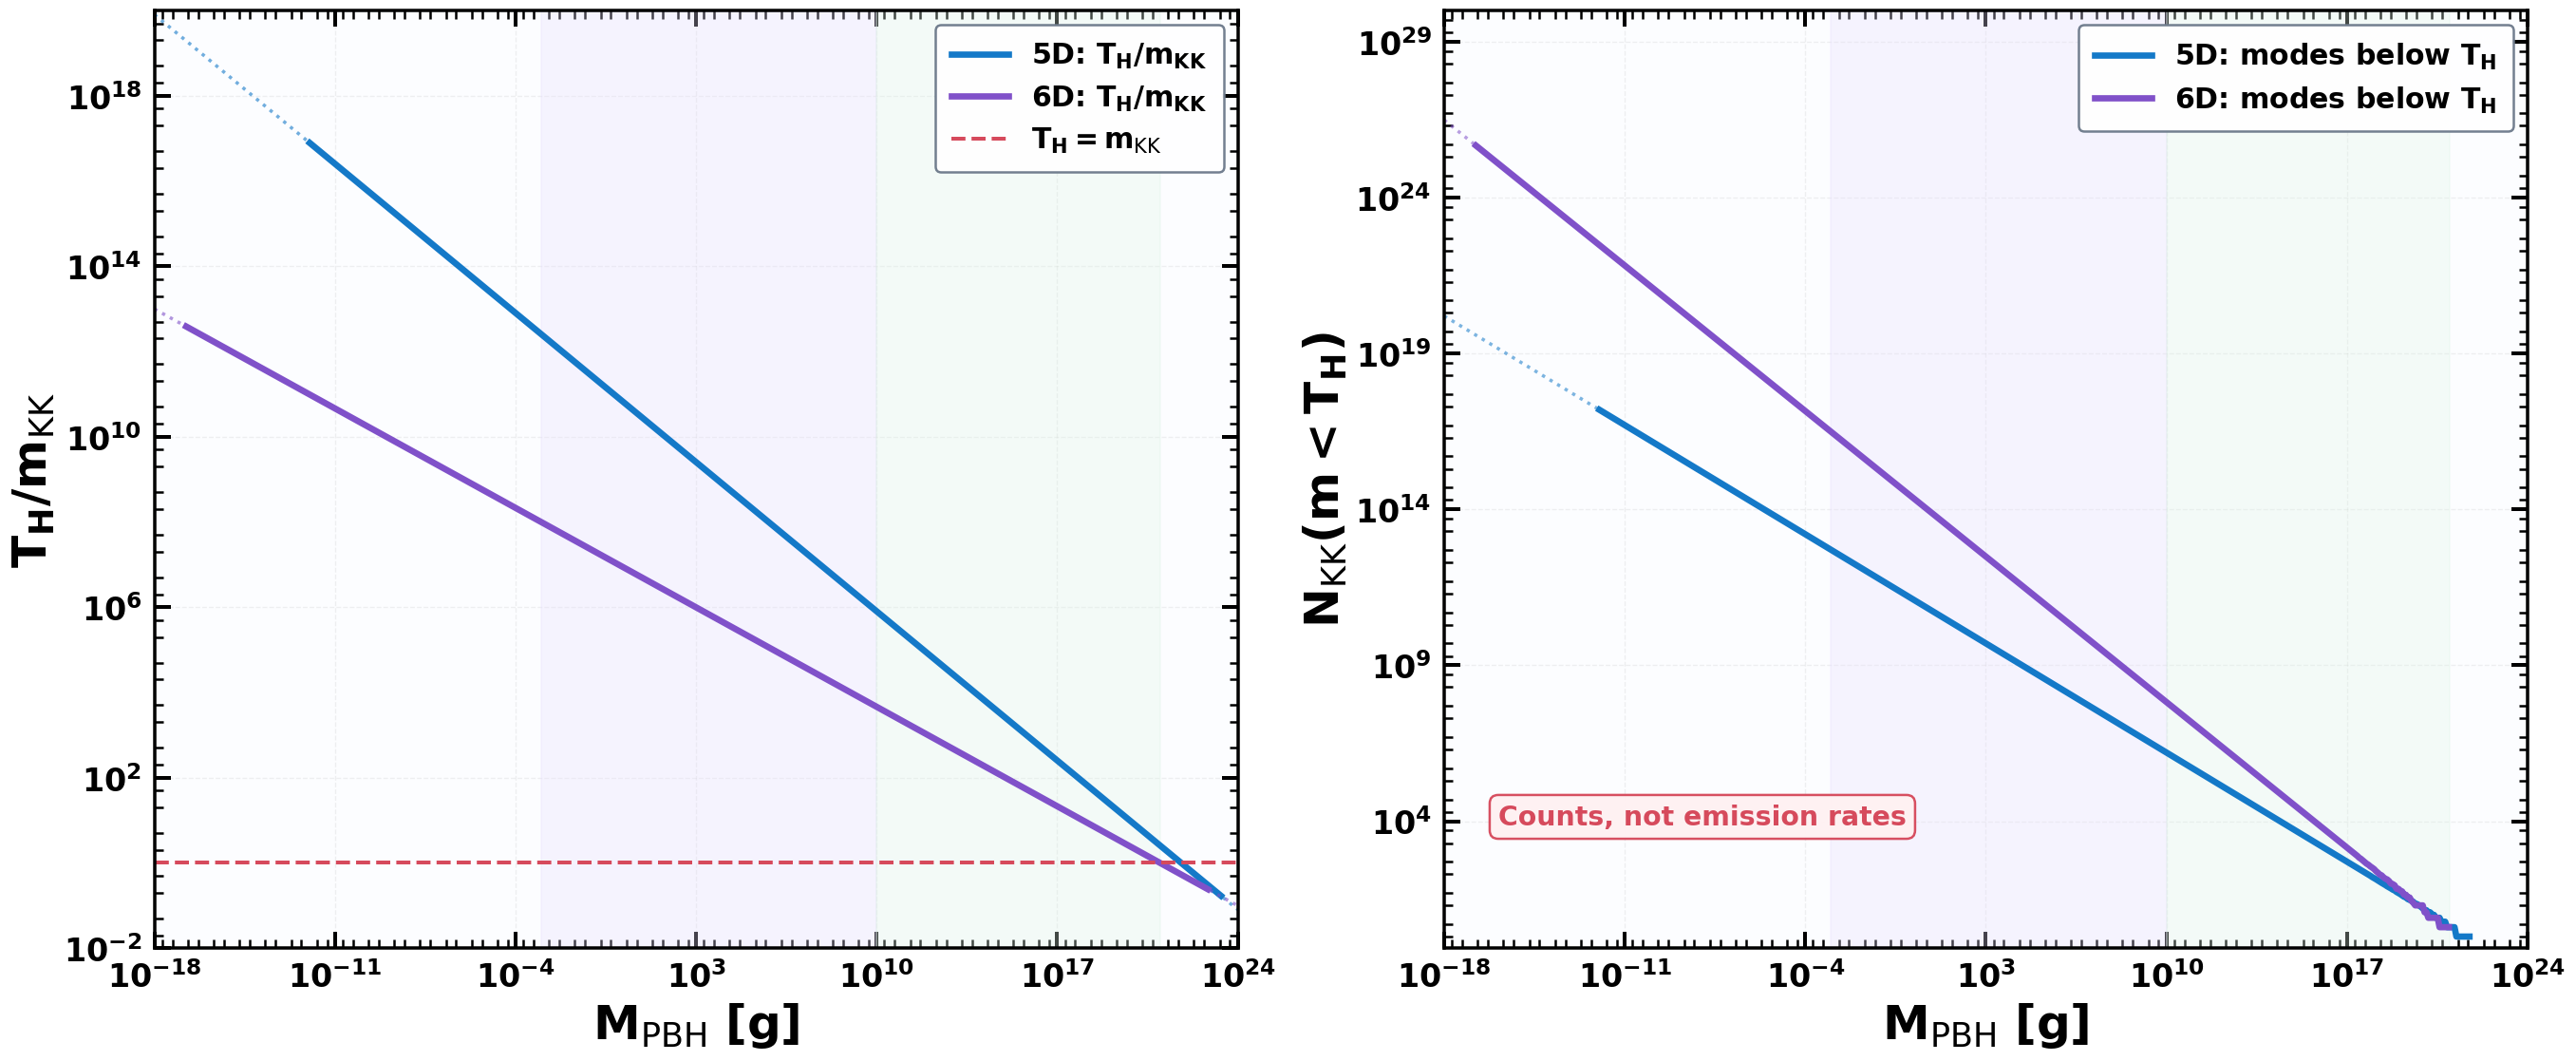

Saved: Supplement_B_Hawking_KK_Accessibility.pdf / .png


In [11]:
# ============== SUPPLEMENT B: KK kinematic thresholds ==============
mg=np.geomspace(1e-18,1e24,580)
fig,(ax,ay)=plt.subplots(1,2,figsize=(22.5,9.2),constrained_layout=True)
for D,col in [(5,'blue'),(6,'purple')]:
    q=T_h(mg,D)*R_GEV
    valid=(r_h(mg,D)<R_GEV)&(mg*G_TO_GEV>1e3*MD_dim(D))
    ax.plot(mg,np.where(valid,q,np.nan),color=C[col],lw=4,label=f'{D}D: $T_H/m_{{KK}}$')
    ax.plot(mg,np.where(~valid,q,np.nan),color=C[col],lw=2.1,ls=':',alpha=.6)
    nk=np.where(D==5,2*np.floor(q),
                np.where(q<=44.8,np.searchsorted(magnitudes,q,side='right')-1,np.pi*q*q))
    nk=np.maximum(nk,0)
    ay.plot(mg,np.where(valid&(nk>=1),nk,np.nan),color=C[col],lw=4,
            label=f'{D}D: modes below $T_H$')
    ay.plot(mg,np.where(~valid&(nk>=1),nk,np.nan),color=C[col],ls=':',lw=2.1,alpha=.55)
ax.axhline(1,color=C['red'],ls='--',lw=2.4,label=r'$T_H=m_{\rm KK}$')
for a in [ax,ay]:
    a.axvspan(1e-3,1e10,color=PASTEL['purple'],alpha=.3)
    a.axvspan(1e10,1e21,color=PASTEL['green'],alpha=.3)
    a.set_xlim(1e-18,1e24)
    a.set_xlabel(r'$\mathbf{M}_{\rm PBH}\ [\mathbf{g}]$')
ax.set_ylim(1e-2,1e20);ay.set_ylim(.85,1e30)
ax.set_ylabel(r'$\mathbf{T}_H/\mathbf{m}_{\rm KK}$')
ay.set_ylabel(r'$\mathbf{N}_{\rm KK}(m<T_H)$')
for a in [ax,ay]:
    style(a,True,True,label=30,ticks=20,xexp=[-18,-11,-4,3,10,17,24])
    legend(a,'upper right',fs=18)
box(ay,'Counts, not emission rates',.05,.14,'red',17,fc='#FFF1F2')
save_show(fig,'Supplement_B_Hawking_KK_Accessibility',dpi=195)

## Supplemental Figure C — Individual KK-shell degeneracies

For one compact direction, each nonzero integer level has multiplicity two ($\pm\ell$). In two compact directions, distinct pairs $(\ell_1,\ell_2)$ can have the same length, and the multiplicity is the number of lattice points on the shell

$$
\ell_1^2+\ell_2^2=N,\qquad m_N=\frac{\sqrt N}{R},\qquad
 g_N=\#\{(\ell_1,\ell_2)\in\mathbb Z^2:\ell_1^2+\ell_2^2=N\}.
$$

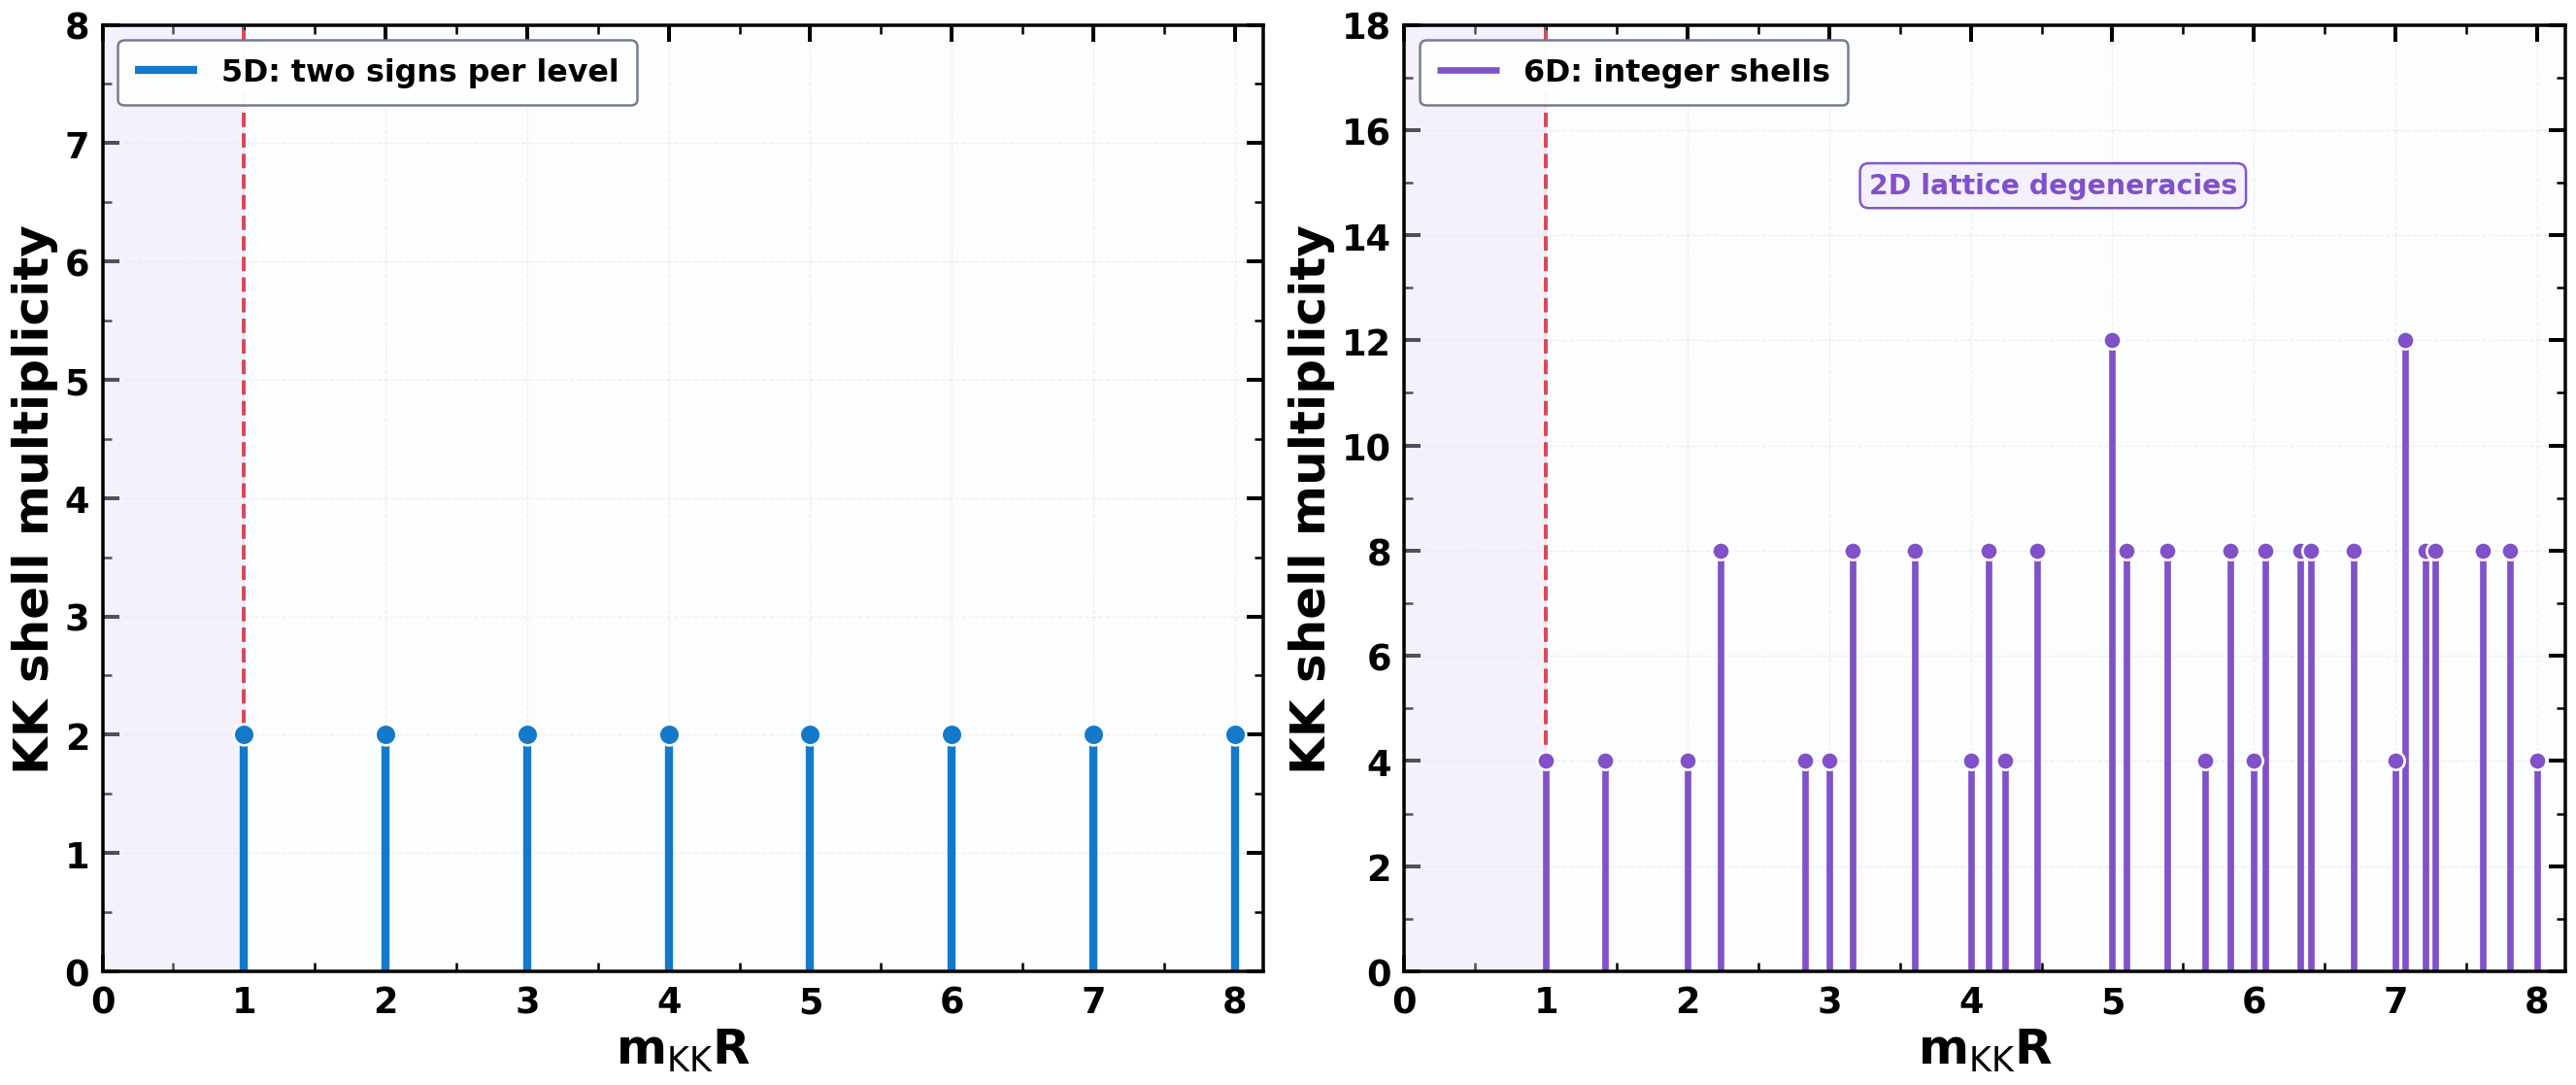

Saved: Supplement_C_KK_Degeneracies.pdf / .png


In [12]:
# ============== SUPPLEMENT C: Exact shell degeneracies ==============
qmax=9
v=np.arange(-qmax,qmax+1)
lsq=(v[:,None]**2+v[None,:]**2).ravel()
vals,counts=np.unique(lsq,return_counts=True)
keep=(vals>0)&(np.sqrt(vals)<=8.05)
lev6=np.sqrt(vals[keep]);g6=counts[keep]
lev5=np.arange(1,9);g5=np.full_like(lev5,2)
fig,(ax,ay)=plt.subplots(1,2,figsize=(22,9.2),constrained_layout=True)
for a in [ax,ay]:
    a.set(xlim=(0,8.2),ylim=(0,18))
    a.axvspan(0,1,color=PASTEL['purple'],alpha=.36)
    a.axvline(1,color=C['red'],ls='--',lw=2.4)
    a.set_xlabel(r'$\mathbf{m}_{\rm KK}\mathbf{R}$')
    a.set_ylabel('KK shell multiplicity')
    style(a,label=30,ticks=22)
ax.set_ylim(0,8)
ax.vlines(lev5,0,g5,color=C['blue'],lw=5,label='5D: two signs per level')
ax.plot(lev5,g5,'o',color=C['blue'],ms=13,mec='white',mew=1.6)
ay.vlines(lev6,0,g6,color=C['purple'],lw=4,label='6D: integer shells')
ay.plot(lev6,g6,'o',color=C['purple'],ms=11,mec='white',mew=1.6)
legend(ax,'upper left',fs=19)
legend(ay,'upper left',fs=19)
box(ay,'2D lattice degeneracies',.40,.83,'purple',17,fc='#F5F0FF')
save_show(fig,'Supplement_C_KK_Degeneracies',dpi=190)
np.savetxt(DATA/'SuppC_Degeneracy_5D.dat',np.column_stack([lev5,g5]),
           header='KKmass_over_gap multiplicity5D')
np.savetxt(DATA/'SuppC_Degeneracy_6D.dat',np.column_stack([lev6,g6]),
           header='KKmass_over_gap multiplicity6D')

## Numerical and reproducibility checks

The following tests independently verify the most important physical scales, the exact mode counting, the finiteness of the SIGW output, the covariance matrices, and whether every expected PDF and PNG exists. Each calculation uses the same constants as the plotted figures.

In [13]:
# ========================= NUMERICAL CHECKS =========================
assert abs(mKK_ev-.1973269804)/.1973269804 < .002
assert 5e8 < MD_dim(5) < 7e8
assert 7e3 < MD_dim(6) < 1e4
assert 20 == 2*np.floor(10)
assert int(np.searchsorted(magnitudes,1.01,side='right')-1)==4
assert 900 < peak_f(1e10) < 1200
assert 3 < peak_f(1e15) < 4
assert .003 < peak_f(1e21) < .004
assert np.all(np.isfinite(OMEGA)) and np.all(OMEGA>0)
for name in ['LISA','DECIGO','BBO']:
    cov=FISH[name][0]
    assert cov.shape==(3,3) and np.all(np.linalg.eigvalsh(cov)>0)

expected=[
    'Fig1_Overview_Three_Panels',
    'Fig2_Compactification_KK',
    'Fig3_Horizon_Temperature_Rotation',
    'Fig4_Curvature_Formation',
    'Fig5_SIGW_Detectors',
    'Fig6_Fisher_Corners',
    'Supplement_A_Gravity_Crossover',
    'Supplement_B_Hawking_KK_Accessibility',
    'Supplement_C_KK_Degeneracies'
]
missing=[f'{n}.{ext}' for n in expected for ext in ('pdf','png')
         if not (OUT/f'{n}.{ext}').is_file()]
assert not missing, f'Missing figure outputs: {missing}'
print('All numerical and file checks PASSED.')
print('Figures:',len(expected), 'PDFs +',len(expected),'PNGs.')
print('Numerical tables:',len(list(DATA.glob('*.dat'))))
print('Output folder:',OUT.resolve())

All numerical and file checks PASSED.
Figures: 9 PDFs + 9 PNGs.
Numerical tables: 33
Output folder: D:\Dark-Dimension_projects\DarkDim-Universe_Reveiw\DD_Review_All_Figures
